# Fase 8 — Fluxograma do método e aplicação web

**Detecção de notícias falsas em português e robustez frente à IA generativa**  
Alice Vitória Cordeiro França — IFPR Campus Paranaguá  
Tecnologia em Análise e Desenvolvimento de Sistemas

---

### O que este notebook faz

Fecha o projeto com duas entregas. A primeira é o fluxograma do método, desenhado em código para que mude junto com o pipeline em vez de envelhecer num editor de imagens — já sem a etapa de Power BI, retirada do escopo. A segunda é a aplicação web — interface em Bootstrap e Chart.js sobre uma API em Starlette — que permite à banca submeter um texto e ver a classificação dos três modelos e o efeito da lematização sobre ela.

### Entradas

- `dados/metricas_consolidadas.csv`
- `dados/metricas_corpus.csv`
- `dados/metricas_sinteticas_completas.csv`
- `modelos/ (TF-IDF, clássicos e BERTimbau)`

### Saídas de dados

- `app/index.html (cópia da interface da aplicação)`

### Figuras geradas para o artigo

- `figuras/fig_fluxograma_pipeline.png` — as oito etapas do método, desenhadas em código
- `figuras/fig_sintese.png` — painel de síntese dos resultados do trabalho

Todas as figuras saem deste notebook, em PNG de 400 dpi e 15 cm de largura, prontas para entrar no artigo em escala 1:1. O padrão visual está no módulo `estilo_sbc.py`, gravado no Drive pela célula 2 e idêntico em todas as fases.

## 1. Ambiente

In [1]:
# Monta o Google Drive e fixa a estrutura de pastas do projeto.
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

BASE    = Path('/content/drive/MyDrive/TCC')
DADOS   = BASE / 'dados'
FIGURAS = BASE / 'figuras'
MODELOS = BASE / 'modelos'
for pasta in (DADOS, FIGURAS, MODELOS):
    pasta.mkdir(parents=True, exist_ok=True)

print('projeto :', BASE)
print('dados   :', DADOS)
print('figuras :', FIGURAS)
print('modelos :', MODELOS)


Mounted at /content/drive
projeto : /content/drive/MyDrive/TCC
dados   : /content/drive/MyDrive/TCC/dados
figuras : /content/drive/MyDrive/TCC/figuras
modelos : /content/drive/MyDrive/TCC/modelos


## 2. Padrão visual das figuras

Mesmo módulo das demais fases: a célula grava `estilo_sbc.py` e a seguinte o importa. O cabeçalho do módulo justifica cada decisão visual em relação ao template da SBC.

In [2]:
%%writefile /content/estilo_sbc.py
# -*- coding: utf-8 -*-
"""
estilo_sbc - padrao visual unico para todas as figuras do artigo.

Cada decisao abaixo responde a uma exigencia concreta do template da SBC.

1. Largura de exatamente 15 cm, garantida no arquivo final. E a area util de
   texto do template em A4 com margens laterais de 3 cm. Nao basta pedir
   `figsize`: o `bbox_inches='tight'` do matplotlib recorta ou expande a
   figura conforme o tamanho dos rotulos, e o PNG sai com largura
   imprevisivel - entre 12 e 17 cm, nos testes. A funcao `salvar` normaliza:
   mede o resultado, completa com branco quando falta e reduz quando sobra,
   e grava a resolucao nos metadados do PNG. O Word e o LaTeX passam a
   inserir a imagem no tamanho fisico certo sem ajuste manual, e so por isso
   a afirmacao de escala 1:1 se sustenta.
2. Tipografia entre 9 e 10,5 pt no grafico. Em escala 1:1 isso fica
   proximo do corpo do texto (Times 12 pt): legivel, sem competir com ele.
3. 400 dpi em PNG. O minimo usual para impressao e 300 dpi.
4. Paleta azul / vermelhao / ambar, derivada de Okabe-Ito, que e a
   referencia de cores seguras para daltonismo em figuras cientificas. O par
   azul-laranja e o mais comum na literatura justamente por ser o que
   sobrevive as tres formas de daltonismo. As luminancias valem 0,27, 0,47 e
   0,71: o template preve avaliacao impressa, eventualmente em preto e
   branco, e cores de luminancia proxima colapsam no mesmo cinza.
5. Escala tipografica fechada, de T_PEQUENO a T_DESTAQUE. Toda figura usa
   esses cinco tamanhos e nenhum outro: tamanhos escolhidos caso a caso
   fazem o conjunto parecer montado por pessoas diferentes.
6. Nenhum texto dentro da area de dados. Rotulo de serie vai para a legenda
   abaixo do eixo, valor de referencia vai para a linha de apoio do titulo.
   Texto sobre os dados colide assim que os dados mudam - e o que fez a
   primeira versao destas figuras ficar ilegivel com o corpus real.
7. Moldura aberta (sem as linhas superior e direita), grade apenas no eixo
   de valores e rotulo numerico em cada elemento: o leitor le o valor em
   vez de estima-lo pela altura da barra.
8. Eixo de valores sempre a partir de zero nos graficos de barra. Quando a
   diferenca entre as series e pequena demais para aparecer, troca-se o
   grafico de barras por um dot plot - truncar o eixo exageraria a
   diferenca e seria enganoso.

Uso:
    from estilo_sbc import *
    destino('/content/drive/MyDrive/TCC/figuras')
    fig, ax = plt.subplots(figsize=(LARGURA, 7*CM))
    ...
    salvar(fig, 'fig_exemplo')
"""

import io
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, MaxNLocator
from PIL import Image

# ----------------------------------------------------------------- paleta
# Azul, vermelhao e ambar, da familia Okabe-Ito. O azul foi escurecido em
# relacao ao original para abrir distancia de luminancia dos outros dois e
# alcancar contraste de texto sobre branco.
AZUL    = '#1B4F72'   # serie primaria   (Regressao Logistica) - luminancia 0,27
LARANJA = '#D55E00'   # serie secundaria (Random Forest)       - luminancia 0,47
AMBAR   = '#E8B04B'   # serie terciaria  (BERTimbau)           - luminancia 0,71
VERDE   = '#117733'   # acento, so quando existe uma quarta serie
TEXTO   = '#1A1A1A'
SUAVE   = '#5F6B7A'
GRADE   = '#E4E7EA'
NEUTRO  = '#C3C9D0'

PALETA  = [AZUL, LARANJA, AMBAR, VERDE]

# Variantes escurecidas para TEXTO. A luminancia que separa as cores na
# impressao em cinza e justamente o que derruba o contraste delas sobre o
# branco: o vermelhao alcanca 3,9:1 e o ambar 1,9:1, abaixo do minimo de
# 4,5:1 que a WCAG pede para texto deste corpo. Preencher formas com a cor da
# serie e escrever com a variante escura resolve os dois lados.
AZUL_TEXTO    = AZUL       # 8,8:1
LARANJA_TEXTO = '#A64A00'  # 5,8:1
AMBAR_TEXTO   = '#8A6410'  # 5,1:1
VERDE_TEXTO   = '#0E5C28'

_LEGIVEL = {AZUL: AZUL_TEXTO, LARANJA: LARANJA_TEXTO,
            AMBAR: AMBAR_TEXTO, VERDE: VERDE_TEXTO}

# ------------------------------------------------------------ tipografia
# Escala fechada. Nenhuma figura inventa um tamanho fora destes cinco.
T_PEQUENO  = 8.0    # nota de rodape dentro da figura, anotacao secundaria
T_CORPO    = 9.0    # eixos, legenda, linha de apoio do titulo
T_ROTULO   = 9.5    # valor escrito sobre barra ou ponto
T_TITULO   = 10.5   # titulo da figura e de cada painel
T_DESTAQUE = 13.0   # numero isolado em painel de sintese


def legivel(cor):
    """Variante da cor com contraste suficiente para texto sobre branco."""
    return _LEGIVEL.get(cor, cor)


CORES_MODELO = {
    'Regressao Logistica': AZUL,
    'Regressão Logística': AZUL,
    'Random Forest': LARANJA,
    'BERTimbau': AMBAR,
}
CORES_CLASSE = {'Verdadeira': AZUL, 'Falsa': LARANJA}

# Comeca num cinza muito claro, nao em branco puro: com branco as celulas
# de valor zero somem e a matriz perde a forma de matriz.
MAPA_FRIO = LinearSegmentedColormap.from_list('sbc_frio', ['#F1F4F5', AZUL])
MAPA_DIV  = LinearSegmentedColormap.from_list('sbc_div', [AZUL, '#FFFFFF', LARANJA])

# ----------------------------------------------------------------- medidas
CM = 1 / 2.54
LARGURA = 15 * CM          # largura total da area de texto do template
LARGURA_MEIA = 7.2 * CM    # duas figuras lado a lado

# ----------------------------------------------------------------- tipografia
# DejaVu Sans vem instalada no Colab e cobre toda a acentuacao do portugues,
# mas tem apenas dois pesos: normal e negrito. Pedir 'semibold' faz o
# matplotlib emitir aviso e cair no negrito de qualquer forma, por isso os
# pesos aqui sao sempre 'normal' ou 'bold'. Se uma familia com mais pesos
# estiver instalada no ambiente, ela e usada - sem exigir instalacao nenhuma.
_instaladas = {f.name for f in mpl.font_manager.fontManager.ttflist}
FAMILIA = next((f for f in ('Inter', 'Source Sans 3', 'Lato', 'Open Sans',
                            'Liberation Sans', 'DejaVu Sans')
                if f in _instaladas), 'sans-serif')

# ----------------------------------------------------------------- rcParams
mpl.rcParams.update({
    'figure.dpi': 110,
    'savefig.dpi': 400,
    'savefig.bbox': 'tight',
    'savefig.facecolor': 'white',
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',

    'font.family': FAMILIA,
    'font.size': T_CORPO,
    'axes.titlesize': T_TITULO,
    'axes.titleweight': 'bold',
    'axes.titlepad': 12,
    'axes.labelsize': T_CORPO,
    'axes.labelcolor': TEXTO,
    'axes.labelpad': 10,
    'xtick.labelsize': T_CORPO,
    'ytick.labelsize': T_CORPO,
    'legend.fontsize': T_CORPO,

    'text.color': TEXTO,
    'axes.edgecolor': '#B9BDC2',
    'axes.linewidth': 0.8,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.spines.left': False,

    'xtick.color': SUAVE,
    'ytick.color': SUAVE,
    'xtick.direction': 'out',
    'ytick.direction': 'out',
    'xtick.major.size': 0,
    'ytick.major.size': 0,
    'xtick.major.pad': 5,
    'ytick.major.pad': 5,

    'grid.color': GRADE,
    'grid.linewidth': 0.8,
    'axes.grid': False,

    'legend.frameon': False,
    'legend.handlelength': 1.2,
    'legend.handleheight': 1.2,
    'legend.columnspacing': 2.2,
    'legend.borderpad': 0.1,
    'legend.labelspacing': 0.6,

    'axes.prop_cycle': mpl.cycler(color=PALETA),
    'lines.linewidth': 2.0,
    'lines.markersize': 6,
    'patch.linewidth': 0,
})

# ----------------------------------------------------------------- destino
_destino = Path('.')


def destino(pasta):
    """Define a pasta onde salvar() grava as figuras."""
    global _destino
    _destino = Path(pasta)
    _destino.mkdir(parents=True, exist_ok=True)
    return _destino


def salvar(fig, nome, largura_cm=15.0, dpi=400):
    """Grava a figura em PNG com largura fisica exata e dpi nos metadados.

    O matplotlib com bbox_inches='tight' devolve larguras diferentes a cada
    figura, conforme o tamanho dos rotulos. Aqui o resultado e normalizado
    para `largura_cm`: se ficou estreito, completa-se com branco, o que
    preserva o corpo das letras; se ficou largo, reduz-se a imagem inteira,
    e a reducao aplicada e informada na saida. Passe largura_cm=None para
    gravar sem normalizar.
    """
    caminho = _destino / (nome + '.png')
    if largura_cm is None:
        fig.savefig(caminho, dpi=dpi, bbox_inches='tight', facecolor='white')
        print('[figura]', caminho.name, '(sem normalizacao)')
        return caminho

    alvo = int(round(largura_cm / 2.54 * dpi))
    buf = io.BytesIO()
    fig.savefig(buf, format='png', dpi=dpi, bbox_inches='tight',
                facecolor='white')
    buf.seek(0)
    im = Image.open(buf).convert('RGB')
    nota = ''
    if im.width > alvo:
        fator = alvo / im.width
        im = im.resize((alvo, max(1, int(round(im.height * fator)))),
                       Image.LANCZOS)
        nota = '  (reduzida {:.1%})'.format(1 - fator)
    elif im.width < alvo:
        tela = Image.new('RGB', (alvo, im.height), 'white')
        tela.paste(im, ((alvo - im.width) // 2, 0))
        im = tela
        nota = '  (margem branca completada)'
    im.save(caminho, dpi=(dpi, dpi))
    print('[figura] {:<30} {:.1f} x {:.1f} cm{}'
          .format(caminho.name, largura_cm, im.height / dpi * 2.54, nota))
    return caminho


# ----------------------------------------------------------------- helpers
def br(texto):
    """Converte um numero ja formatado para a convencao brasileira.

    Troca o separador decimal por virgula e o de milhar por ponto. Um artigo
    em portugues com "97.40%" no grafico e "97,40%" no texto nao passa pela
    revisao, entao a conversao fica embutida nos helpers de rotulo e nos
    formatadores de eixo - nao depende de lembrar caso a caso.
    """
    return str(texto).replace(',', '\u0000').replace('.', ',').replace('\u0000', '.')


def pct(valor, dec=1):
    """Percentual na convencao brasileira: pct(0.974, 2) -> '97,40%'."""
    return br(('{:.' + str(dec) + 'f}').format(100 * valor)) + '%'


def mil(valor, dec=0):
    """Inteiro com separador de milhar: mil(11902) -> '11.902'."""
    return br(('{:,.' + str(dec) + 'f}').format(valor))


def grade_y(ax, atras=True):
    """Grade horizontal apenas (para barras verticais e linhas)."""
    ax.grid(axis='y', color=GRADE, linewidth=0.8)
    ax.grid(axis='x', visible=False)
    ax.set_axisbelow(atras)
    return ax


def grade_x(ax, atras=True):
    """Grade vertical apenas (para barras horizontais)."""
    ax.grid(axis='x', color=GRADE, linewidth=0.8)
    ax.grid(axis='y', visible=False)
    ax.set_axisbelow(atras)
    return ax


def sem_grade(ax):
    ax.grid(False)
    for lado in ('top', 'right', 'left', 'bottom'):
        ax.spines[lado].set_visible(False)
    ax.set_xticks([])
    ax.set_yticks([])
    return ax


def eixo_percentual(ax, eixo='y', decimais=0):
    f = FuncFormatter(lambda v, _: pct(v, decimais))
    (ax.yaxis if eixo == 'y' else ax.xaxis).set_major_formatter(f)
    return ax


def eixo_decimal(ax, eixo='y', decimais=2):
    """Eixo numerico comum, tambem com virgula decimal."""
    f = FuncFormatter(
        lambda v, _: br(('{:,.' + str(decimais) + 'f}').format(v)))
    (ax.yaxis if eixo == 'y' else ax.xaxis).set_major_formatter(f)
    return ax


def escala_percentual(ax, maximo=1.0, folga_topo=0.20, passo=0.2, decimais=0):
    """Eixo percentual com folga no topo sem inventar marcas acima do maximo.

    Abrir espaco apenas com set_ylim faz o matplotlib desenhar marcas de 110%
    ou 120% num eixo de acuracia, o que nao existe. Aqui a folga e so espaco
    em branco: as marcas param no maximo real.
    """
    import numpy as _np
    ax.set_ylim(0, maximo * (1 + folga_topo))
    ax.set_yticks(_np.round(_np.arange(0, maximo + 1e-9, passo), 10))
    eixo_percentual(ax, 'y', decimais)
    return ax


def eixo_milhar(ax, eixo='y'):
    f = FuncFormatter(lambda v, _: mil(v))
    (ax.yaxis if eixo == 'y' else ax.xaxis).set_major_formatter(f)
    return ax


def rotular(ax, barras, fmt='{:.1%}', dy=5, tam=T_ROTULO, peso='bold', cor=None):
    """Escreve o valor acima de cada barra vertical."""
    for b in barras:
        v = b.get_height()
        ax.annotate(br(fmt.format(v)),
                    xy=(b.get_x() + b.get_width() / 2, v),
                    xytext=(0, dy), textcoords='offset points',
                    ha='center', va='bottom',
                    fontsize=tam, fontweight=peso,
                    color=cor or TEXTO)
    return ax


def rotular_h(ax, barras, fmt='{:.1%}', dx=6, tam=T_ROTULO, peso='bold', cor=None):
    """Escreve o valor a direita de cada barra horizontal."""
    for b in barras:
        v = b.get_width()
        ax.annotate(br(fmt.format(v)),
                    xy=(v, b.get_y() + b.get_height() / 2),
                    xytext=(dx, 0), textcoords='offset points',
                    ha='left', va='center',
                    fontsize=tam, fontweight=peso,
                    color=cor or TEXTO)
    return ax


def encolher_para_caber(ax, textos, largura_dados, tamanho, minimo=6.5,
                        passo=0.2):
    """Reduz o corpo de um conjunto de textos ate o mais largo caber.

    Mede a largura real de cada texto na figura renderizada, em vez de
    confiar numa estimativa por numero de caracteres - a largura depende da
    fonte, do peso e de quais letras sao. O mesmo tamanho e aplicado a todos
    os textos do conjunto: encolher so o que transborda deixaria um rotulo
    menor que os vizinhos, o que aparece mais do que o problema original.
    """
    fig = ax.figure
    fig.canvas.draw()
    renderizador = fig.canvas.get_renderer()
    base = ax.transData.transform((0, 0))[0]
    limite = ax.transData.transform((largura_dados, 0))[0] - base
    while tamanho > minimo:
        maior = max(t.get_window_extent(renderer=renderizador).width
                    for t in textos)
        if maior <= limite:
            break
        tamanho -= passo
        for t in textos:
            t.set_fontsize(tamanho)
    return tamanho


def legenda_abaixo(ax, ncols=2, afastamento=None, **kwargs):
    """Legenda centralizada abaixo do eixo, fora da area de dados.

    Posicao unica para todas as figuras do artigo, por dois motivos. O
    primeiro e consistencia: legenda ora dentro, ora fora, faz o conjunto
    parecer montado aos pedacos. O segundo e que legenda dentro do grafico
    so fica livre por acaso - ela nao sabe onde estao os dados, e basta o
    corpus mudar para ela cair em cima deles.
    """
    # O afastamento e calculado em pontos e so depois convertido para
    # fracao do eixo. Usar uma fracao fixa afasta a legenda de forma
    # diferente em cada figura - num grafico de barras horizontais, alto, a
    # mesma fracao joga a legenda muito mais para baixo do que num grafico
    # baixo, e em alguns casos ela sobe por cima do rotulo do eixo.
    altura_pt = (ax.get_position().height * ax.figure.get_figheight() * 72) or 1
    if afastamento is None:
        afastamento = -(44 if ax.get_xlabel() else 24) / altura_pt
    return ax.legend(loc='upper center', ncols=ncols,
                     bbox_to_anchor=(0.5, afastamento),
                     fontsize=T_CORPO, **kwargs)


def legenda_manual(ax, itens, ncols=None, **kwargs):
    """Legenda abaixo do eixo montada a partir de (rotulo, cor).

    Para graficos cujos artistas nao carregam rotulo - area empilhada,
    histograma desenhado em duas passagens, barras coloridas uma a uma.
    """
    from matplotlib.patches import Patch
    marcas = [Patch(facecolor=cor, label=rotulo) for rotulo, cor in itens]
    return legenda_abaixo(ax, ncols=ncols or len(itens), handles=marcas,
                          **kwargs)


def titulo(ax, principal, apoio=None):
    """Titulo em duas linhas: a afirmacao e, abaixo, a leitura de apoio.

    A linha de apoio e desenhada como anotacao acima do eixo, entao o
    afastamento do titulo precisa acomoda-la - com o `pad` padrao os dois
    se sobrepoem.
    """
    linhas_apoio = apoio.count('\n') + 1 if apoio else 0
    ax.set_title(principal, loc='left',
                 pad=(25 + 12 * (linhas_apoio - 1)) if apoio else 10)
    if apoio:
        ax.annotate(apoio, xy=(0, 1), xycoords='axes fraction',
                    xytext=(0, 7), textcoords='offset points',
                    ha='left', va='bottom', fontsize=T_CORPO, color=SUAVE)
    return ax


def espacar(valores, minimo):
    """Afasta rotulos proximos demais para que nao se sobreponham.

    Devolve posicoes verticais na mesma unidade dos valores, preservando a
    ordem original. Usada quando varias series terminam em valores vizinhos:
    sem isso os rotulos se empilham e nenhum fica legivel.
    """
    import numpy as _np
    valores = _np.asarray(valores, dtype=float)
    pos = valores.copy()
    ordem = _np.argsort(valores)
    for k in range(1, len(ordem)):
        anterior, atual = ordem[k - 1], ordem[k]
        if pos[atual] - pos[anterior] < minimo:
            pos[atual] = pos[anterior] + minimo
    deslocamento = pos[ordem].mean() - valores[ordem].mean()
    return pos - deslocamento


def folga(ax, eixo='y', fator=0.14):
    """Abre espaco no topo para os rotulos nao encostarem na borda."""
    if eixo == 'y':
        lo, hi = ax.get_ylim()
        ax.set_ylim(lo, hi + (hi - lo) * fator)
    else:
        lo, hi = ax.get_xlim()
        ax.set_xlim(lo, hi + (hi - lo) * fator)
    return ax


def painel_confusao(ax, matriz, titulo_painel, rotulos=('Verdadeira', 'Falsa'),
                    destaque=None):
    """Matriz de confusao 2x2 com contagem e percentual por celula."""
    import numpy as np
    matriz = np.asarray(matriz, dtype=float)
    total = matriz.sum()
    ax.imshow(matriz / matriz.max(), cmap=MAPA_FRIO, vmin=0, vmax=1.15)
    for i in range(matriz.shape[0]):
        for j in range(matriz.shape[1]):
            v = matriz[i, j]
            claro = (v / matriz.max()) > 0.55
            ax.text(j, i - 0.10, mil(v),
                    ha='center', va='center', fontsize=T_DESTAQUE,
                    fontweight='bold',
                    color='white' if claro else TEXTO)
            ax.text(j, i + 0.22, pct(v / total, 1),
                    ha='center', va='center', fontsize=T_PEQUENO,
                    color='#E8EEF0' if claro else SUAVE)
    ax.set_xticks([0, 1], ['Predita\n' + rotulos[0], 'Predita\n' + rotulos[1]])
    ax.set_yticks([0, 1], ['Real\n' + rotulos[0], 'Real\n' + rotulos[1]])
    ax.set_title(titulo_painel, loc='center', pad=10,
                 color=legivel(destaque) if destaque else TEXTO)
    for lado in ('top', 'right', 'left', 'bottom'):
        ax.spines[lado].set_visible(False)
    ax.tick_params(length=0)
    ax.grid(False)
    return ax


def barras_pareadas(ax, categorias, series, fmt='{:.1%}', largura_grupo=0.78,
                    rotulo=True):
    """Barras agrupadas. `series` e uma lista de (nome, valores, cor)."""
    import numpy as np
    x = np.arange(len(categorias))
    n = len(series)
    larg = largura_grupo / n
    for k, (nome, valores, cor) in enumerate(series):
        desloc = (k - (n - 1) / 2) * larg
        b = ax.bar(x + desloc, valores, larg * 0.92, label=nome, color=cor)
        if rotulo:
            rotular(ax, b, fmt=fmt, tam=T_PEQUENO)
    ax.set_xticks(x, categorias)
    grade_y(ax)
    return ax


print('estilo_sbc carregado  |  paleta', AZUL, LARANJA, AMBAR)


Writing /content/estilo_sbc.py


In [3]:
# Copia o modulo para o Drive (fica versionado junto com o projeto) e importa.
import shutil, sys
shutil.copy('/content/estilo_sbc.py', BASE / 'estilo_sbc.py')
sys.path.insert(0, '/content')

from estilo_sbc import *      # noqa: F401,F403
destino(FIGURAS)

import numpy as np
import pandas as pd


estilo_sbc carregado  |  paleta #1B4F72 #D55E00 #E8B04B


## 3. Localizadores de arquivos e colunas

In [4]:
# Os arquivos podem estar em TCC/ ou em TCC/dados/; procura nos dois.

def arquivo(*nomes):
    """Primeiro dos nomes que existir em dados/ ou na raiz."""
    tentados = []
    for nome in nomes:
        for pasta in (DADOS, BASE):
            alvo = pasta / nome
            tentados.append(str(alvo))
            if alvo.exists():
                return alvo
    raise FileNotFoundError(
        'Nenhum destes arquivos foi encontrado:\n  ' + '\n  '.join(tentados))


def existe(*nomes):
    try:
        return arquivo(*nomes)
    except FileNotFoundError:
        return None


def coluna(df, *candidatos, obrigatoria=True):
    """Resolve o nome real de uma coluna a partir de varios candidatos."""
    mapa = {c.strip().lower(): c for c in df.columns}
    for cand in candidatos:
        if cand.strip().lower() in mapa:
            return mapa[cand.strip().lower()]
    for cand in candidatos:
        chave = cand.strip().lower()
        for norm, orig in mapa.items():
            if chave in norm:
                return orig
    if obrigatoria:
        raise KeyError('Nenhuma destas colunas existe: ' + ', '.join(candidatos)
                       + '\nDisponiveis: ' + ', '.join(map(str, df.columns)))
    return None


def csvs_do_projeto():
    """Todos os CSV sob a pasta do projeto, com contagem de linhas e colunas."""
    achados = []
    for caminho in sorted(BASE.rglob('*.csv')):
        try:
            cabecalho = list(pd.read_csv(caminho, nrows=0).columns)
            with open(caminho, encoding='utf-8', errors='ignore') as fh:
                linhas = max(sum(1 for _ in fh) - 1, 0)
        except Exception as erro:
            cabecalho, linhas = ['<ilegível: {}>'.format(erro)], -1
        achados.append((caminho, linhas, cabecalho))
    return achados


def listar_csvs():
    """Inventário dos CSV da pasta do projeto."""
    achados = csvs_do_projeto()
    if not achados:
        print('nenhum CSV encontrado em', BASE)
        return
    for caminho, linhas, colunas in achados:
        print('{:<44} {:>7} linhas   {}'.format(
            str(caminho.relative_to(BASE)), linhas,
            ', '.join(map(str, colunas))[:88]))


def procurar_csv(*pistas_de_coluna, nomes=()):
    """Acha um CSV pelo nome e, falhando isso, pelas colunas."""
    if nomes:
        alvo = existe(*nomes)
        if alvo is not None:
            return alvo
    candidatos = []
    for caminho, linhas, colunas in csvs_do_projeto():
        normalizadas = {str(c).strip().lower() for c in colunas}
        if any(any(pista in c for c in normalizadas) for pista in pistas_de_coluna):
            candidatos.append((linhas, caminho))
    if candidatos:
        candidatos.sort(reverse=True)
        escolhido = candidatos[0][1]
        print('localizado pelo conteúdo:', escolhido.relative_to(BASE))
        if len(candidatos) > 1:
            print('outros compatíveis:',
                  [str(c.relative_to(BASE)) for _, c in candidatos[1:]])
        return escolhido
    print('Nenhum CSV com coluna parecida com', pistas_de_coluna, 'foi encontrado.')
    print('Nomes procurados:', nomes or '(nenhum)')
    print('\nCSVs disponíveis em', BASE, ':')
    listar_csvs()
    raise FileNotFoundError(
        'Veja o inventário acima e renomeie o arquivo certo, ou gere-o de novo.')


def modelos_disponiveis():
    """(pasta, data, convencao) de cada modelo salvo sob o projeto.

    A convencao vem de convencao_rotulo.json, gravado pela Fase 5: sem ela
    nao da para saber se o rotulo 1 do modelo significa falsa ou verdadeira.
    """
    import datetime as _dt
    import json as _json
    achados = []
    for config in sorted(BASE.rglob('config.json')):
        pasta = config.parent
        if not (pasta / 'model.safetensors').exists() \
                and not (pasta / 'pytorch_model.bin').exists():
            continue
        marca = pasta / 'convencao_rotulo.json'
        convencao = None
        if marca.exists():
            try:
                convencao = _json.loads(marca.read_text(encoding='utf-8'))
            except Exception:
                convencao = {'erro': 'json ilegivel'}
        achados.append((pasta,
                        _dt.datetime.fromtimestamp(config.stat().st_mtime),
                        convencao))
    return sorted(achados, key=lambda t: t[1], reverse=True)


def listar_modelos():
    achados = modelos_disponiveis()
    if not achados:
        print('nenhum modelo encontrado em', BASE)
        return
    for pasta, quando, convencao in achados:
        print('{:<46} {}  {}'.format(
            str(pasta.relative_to(BASE)), quando.strftime('%d/%m %H:%M'),
            'rótulo 1 = ' + convencao.get('1', '?') if convencao
            else 'SEM convenção declarada'))


def achar_modelo(convencao_exigida='Falsa'):
    """Pasta do BERTimbau ajustado que declare a convencao de rotulo pedida.

    Escolher por uma lista fixa de nomes nao distingue o modelo desta
    execucao de um modelo antigo salvo no mesmo caminho, e um modelo
    treinado sob a convencao oposta acerta menos que o acaso.
    """
    disponiveis = [t for t in modelos_disponiveis()
                   if 'checkpoint' not in t[0].name]
    if not disponiveis:
        return None

    corretos = [t for t in disponiveis
                if t[2] and t[2].get('1') == convencao_exigida]
    if corretos:
        return str(corretos[0][0])

    print('AVISO: nenhum modelo declara a convenção "rótulo 1 =',
          convencao_exigida, '". Usando o mais recente; confira a acurácia.')
    listar_modelos()
    return str(disponiveis[0][0])


_NLP = None


def motor_lema():
    """Carrega o spaCy português uma vez por sessão."""
    global _NLP
    if _NLP is None:
        import spacy
        try:
            _NLP = spacy.load('pt_core_news_sm', disable=['parser', 'ner'])
        except OSError:
            import subprocess, sys
            subprocess.run([sys.executable, '-m', 'spacy', 'download',
                            'pt_core_news_sm'], check=True)
            _NLP = spacy.load('pt_core_news_sm', disable=['parser', 'ner'])
    return _NLP


def lematizar(textos, lote=32):
    """Reduz cada texto à sequência de lemas, como o corpus foi distribuído."""
    nlp = motor_lema()
    return [' '.join(t.lemma_ for t in doc)
            for doc in nlp.pipe(list(textos), batch_size=lote)]


def taxa_de_lema(textos, limite=400):
    """Fração de tokens alfabéticos que já coincidem com o próprio lema.

    Mede o quanto um conjunto já está na forma lematizada: o corpus fica
    acima de 0,90 e o português corrente, perto de 0,60.
    """
    nlp = motor_lema()
    iguais = total = 0
    for doc in nlp.pipe(list(textos)[:limite], batch_size=32):
        for t in doc:
            if t.is_alpha and len(t.text) > 2:
                total += 1
                iguais += t.text.lower() == t.lemma_.lower()
    return iguais / total if total else float('nan')


## 4. Figura — fluxograma do método

Desenhado com `matplotlib` em vez de uma ferramenta de diagramas por dois motivos: entra no artigo com a mesma tipografia e a mesma paleta das outras figuras, e acompanha mudanças do pipeline sem retrabalho manual. As duas colunas separam a construção dos modelos, à esquerda, da avaliação adversária, à direita.

[figura] fig_fluxograma_pipeline.png    15.0 x 8.7 cm  (margem branca completada)


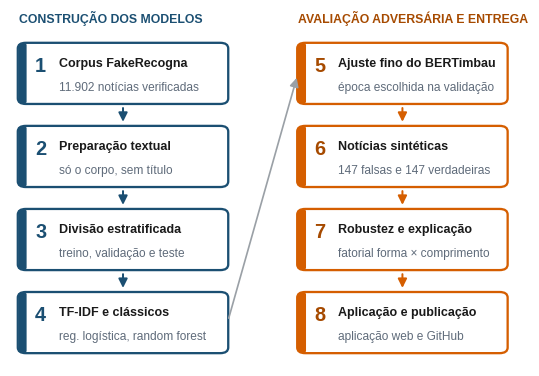

In [5]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

etapas = [
    ('1', 'Corpus FakeRecogna',       '11.902 notícias verificadas'),
    ('2', 'Preparação textual',       'só o corpo, sem título'),
    ('3', 'Divisão estratificada',    'treino, validação e teste'),
    ('4', 'TF-IDF e clássicos',       'reg. logística, random forest'),
    ('5', 'Ajuste fino do BERTimbau', 'época escolhida na validação'),
    ('6', 'Notícias sintéticas',      '147 falsas e 147 verdadeiras'),
    ('7', 'Robustez e explicação',    'fatorial forma × comprimento'),
    ('8', 'Aplicação e publicação',   'aplicação web e GitHub'),
]
CORES_COLUNA = [AZUL, LARANJA]

fig, ax = plt.subplots(figsize=(LARGURA, 10.6 * CM))
ax.set_xlim(0, 10); ax.set_ylim(0.55, 10.55); sem_grade(ax)

# A coluna da esquerda vai de 0,15 a 4,30 e a da direita de 5,70 a 9,85: o
# corredor central de 1,4 unidade existe para a seta que troca de coluna
# passar sem cruzar caixa nenhuma.
L, A = 4.15, 1.70
col_x = [0.15, 5.70]
linha_y = [7.95, 5.60, 3.25, 0.90]
centros = {}
titulos, apoios = [], []

for i, (num, nome, apoio) in enumerate(etapas):
    c = i // 4
    x, y = col_x[c], linha_y[i % 4]
    cor = CORES_COLUNA[c]
    ax.add_patch(FancyBboxPatch((x, y), L, A,
                                boxstyle='round,pad=0.015,rounding_size=0.16',
                                facecolor='white', edgecolor=cor, linewidth=1.5))
    ax.add_patch(FancyBboxPatch((x, y), 0.16, A,
                                boxstyle='round,pad=0,rounding_size=0.05',
                                facecolor=cor, edgecolor='none'))
    ax.text(x + 0.44, y + A * 0.62, num, fontsize=T_DESTAQUE, fontweight='bold',
            color=legivel(cor), ha='center', va='center')
    titulos.append(
        ax.text(x + 0.80, y + A * 0.66, nome, fontsize=T_CORPO,
                fontweight='bold', color=TEXTO, ha='left', va='center'))
    apoios.append(
        ax.text(x + 0.80, y + A * 0.26, apoio, fontsize=T_PEQUENO, color=SUAVE,
                ha='left', va='center'))
    centros[i] = (x, y, L, A)


# Medir o texto renderizado e a unica forma confiavel de saber se ele cabe:
# a largura depende da fonte e de quais letras sao, nao do numero de
# caracteres.
UTIL = L - 0.80 - 0.18
encolher_para_caber(ax, titulos, UTIL, T_CORPO)
encolher_para_caber(ax, apoios, UTIL, T_PEQUENO)


def flecha(a, b, cor, largura=1.3):
    xa, ya, La, Aa = centros[a]
    xb, yb, Lb, Ab = centros[b]
    if abs(xa - xb) < 0.1:                       # mesma coluna: desce
        p0, p1 = (xa + La / 2, ya), (xb + Lb / 2, yb + Ab)
    else:                                        # troca de coluna: sobe pelo meio
        p0, p1 = (xa + La, ya + Aa / 2), (xb, yb + Ab / 2)
    ax.add_patch(FancyArrowPatch(p0, p1, arrowstyle='-|>', mutation_scale=12,
                                 color=cor, linewidth=largura,
                                 connectionstyle='arc3,rad=0',
                                 shrinkA=3, shrinkB=3, zorder=1))


for i in (0, 1, 2):
    flecha(i, i + 1, AZUL)
flecha(3, 4, '#9AA0A6', largura=1.1)             # transição entre colunas
for i in (4, 5, 6):
    flecha(i, i + 1, LARANJA)

ax.text(col_x[0], 10.15, 'CONSTRUÇÃO DOS MODELOS', fontsize=T_PEQUENO,
        fontweight='bold', color=AZUL, ha='left', va='bottom')
ax.text(col_x[1], 10.15, 'AVALIAÇÃO ADVERSÁRIA E ENTREGA', fontsize=T_PEQUENO,
        fontweight='bold', color=LARANJA_TEXTO, ha='left', va='bottom')

salvar(fig, 'fig_fluxograma_pipeline')
plt.show()


## 5. Figura — painel de síntese

Um painel único com o que o trabalho mediu: escala do corpus, desempenho no conjunto original e queda sob texto sintético. Serve à apresentação, onde o slide precisa carregar o argumento inteiro de uma vez, mais do que ao artigo, onde cada resultado tem a sua figura.

[figura] fig_sintese.png                15.0 x 10.2 cm  (margem branca completada)


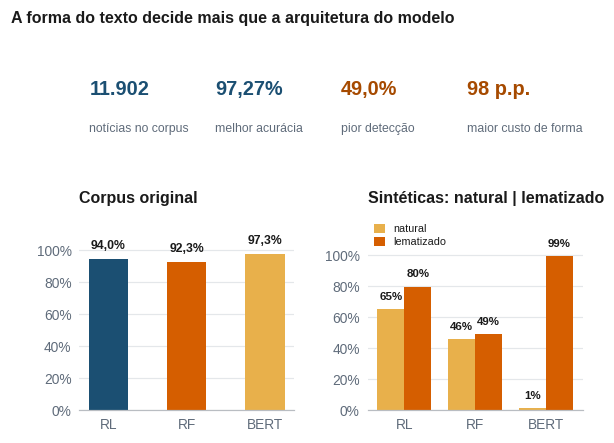

In [6]:
c = pd.read_csv(arquivo('metricas_consolidadas.csv'), index_col=0)
corpus = pd.read_csv(arquivo('metricas_corpus.csv'), index_col=0)

fig = plt.figure(figsize=(LARGURA, 10.2 * CM))
malha = fig.add_gridspec(2, 2, height_ratios=[0.40, 1], hspace=0.52, wspace=0.34)

ax0 = fig.add_subplot(malha[0, :]); sem_grade(ax0)
total = int(corpus.loc['Total'].iloc[0]) if 'Total' in corpus.index else 11902
cartoes = [
    (mil(total), 'notícias no corpus', AZUL),
    (pct(c['acuracia'].max(), 2), 'melhor acurácia', AZUL),
    (pct(c['deteccao_lematizada'].min()), 'pior detecção', LARANJA_TEXTO),
    (mil(c['custo_descasamento_pp'].abs().max()) + ' p.p.',
     'maior custo de forma', LARANJA_TEXTO),
]
for k, (valor, legenda, cor) in enumerate(cartoes):
    x = 0.02 + k * 0.25
    ax0.text(x, 0.76, valor, fontsize=T_DESTAQUE, fontweight='bold', color=cor,
             ha='left', va='center', transform=ax0.transAxes)
    ax0.text(x, 0.24, legenda, fontsize=T_PEQUENO, color=SUAVE,
             ha='left', va='center', transform=ax0.transAxes)

ax1 = fig.add_subplot(malha[1, 0])
b = ax1.bar(c.index, c['acuracia'], color=[CORES_MODELO[i] for i in c.index],
            width=0.5)
rotular(ax1, b, fmt='{:.1%}', tam=T_PEQUENO)
escala_percentual(ax1, folga_topo=0.20); grade_y(ax1)
ax1.set_xticks(range(len(c)), ['RL', 'RF', 'BERT'])
titulo(ax1, 'Corpus original')

ax2 = fig.add_subplot(malha[1, 1])
largura = 0.38
x = np.arange(len(c))
b1 = ax2.bar(x - largura / 2, c['deteccao_natural'], width=largura,
             color=AMBAR, label='natural')
b2 = ax2.bar(x + largura / 2, c['deteccao_lematizada'], width=largura,
             color=LARANJA, label='lematizado')
rotular(ax2, b1, fmt='{:.0%}', tam=T_PEQUENO - 0.5)
rotular(ax2, b2, fmt='{:.0%}', tam=T_PEQUENO - 0.5)
escala_percentual(ax2, folga_topo=0.24); grade_y(ax2)
ax2.set_xticks(x, ['RL', 'RF', 'BERT'])
titulo(ax2, 'Sintéticas: natural | lematizado')
# Legenda dentro do painel: num gridspec, legenda abaixo do eixo estica o
# bbox salvo e a figura inteira sai deformada.
ax2.legend(loc='upper left', fontsize=T_PEQUENO - 1, frameon=False,
           handlelength=1.0, handleheight=0.9, borderpad=0.1,
           labelspacing=0.25)

fig.suptitle('A forma do texto decide mais que a arquitetura do modelo',
             x=0.02, y=1.015, ha='left', fontsize=T_TITULO, fontweight='bold')
salvar(fig, 'fig_sintese')
plt.show()


## 6. Aplicação web

Interface em HTML com Bootstrap 5 e Chart.js, servida por uma API em Starlette sobre Uvicorn. O servidor roda em segundo plano no próprio Colab: a célula termina, o endereço fica disponível e as células seguintes podem ser executadas normalmente.

A entrada é lematizada antes de chegar aos modelos. Sem esse passo a aplicação classificaria quase toda notícia falsa como verdadeira, porque os modelos foram treinados sobre texto lematizado e o usuário digita português corrente — o descasamento medido na Fase 7. A interface mostra o texto na forma em que os modelos o leem e o que cada um responderia sem a correção.

Esta fase não precisa de GPU.

In [7]:
import importlib.util, subprocess, sys
faltando = [p for p in ('starlette', 'uvicorn') if importlib.util.find_spec(p) is None]
if faltando:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *faltando], check=True)

import json
import joblib, torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

Path('/content/app_web').mkdir(parents=True, exist_ok=True)

vec = joblib.load(MODELOS / 'tfidf.joblib')
lr = joblib.load(MODELOS / 'regressao_logistica.joblib')
rf = joblib.load(MODELOS / 'random_forest.joblib')

caminho = achar_modelo()
if caminho is None:
    raise FileNotFoundError('Nenhum BERTimbau salvo em modelos/. Rode a Fase 5 antes.')
marca = Path(caminho) / 'convencao_rotulo.json'
info_modelo = json.loads(marca.read_text(encoding='utf-8')) if marca.exists() else {}
if info_modelo.get('1') != 'Falsa':
    raise ValueError('O modelo em {} não declara "rótulo 1 = Falsa". Rode a Fase 5 de novo.'.format(caminho))

tok = AutoTokenizer.from_pretrained(caminho)
bert = AutoModelForSequenceClassification.from_pretrained(caminho).eval()
disp = 'cuda' if torch.cuda.is_available() else 'cpu'
bert.to(disp)
nlp = motor_lema()


@torch.no_grad()
def p_bert(textos):
    """Probabilidade de 'falsa' (rótulo 1) para cada texto."""
    ent = tok(list(textos), truncation=True, max_length=256,
              padding=True, return_tensors='pt').to(disp)
    return torch.softmax(bert(**ent).logits, -1)[:, 1].cpu().numpy()


def n_subpalavras(texto):
    return len(tok(texto)['input_ids'])


print('modelos carregados')
print('  BERTimbau:', Path(caminho).name, '| treinado em', info_modelo.get('treinado_em', '?'),
      '| dispositivo:', disp)


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

modelos carregados
  BERTimbau: bertimbau_final | treinado em 2026-10-17T17:14:29 | dispositivo: cpu


### 6.1. Interface

Página única: análise do texto, resultados da pesquisa e descrição do método. Os números da aba de resultados vêm dos CSV das fases anteriores, não estão escritos na página.

In [8]:
%%writefile /content/app_web/index.html
<!doctype html>
<html lang="pt-BR">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Detector de notícias falsas</title>
<link rel="preconnect" href="https://fonts.googleapis.com">
<link rel="preconnect" href="https://fonts.gstatic.com" crossorigin>
<link href="https://fonts.googleapis.com/css2?family=Instrument+Sans:wght@400;500;600;700&family=Newsreader:opsz,wght@6..72,400;6..72,500;6..72,600&display=swap" rel="stylesheet">
<link href="https://cdn.jsdelivr.net/npm/bootstrap@5.3.3/dist/css/bootstrap.min.css" rel="stylesheet">
<link href="https://cdn.jsdelivr.net/npm/bootstrap-icons@1.11.3/font/bootstrap-icons.min.css" rel="stylesheet">
<style>
:root {
  --tinta: #13293D;
  --azul: #1B4F72;
  --azul-escuro: #143B56;
  --azul-claro: #E3ECF2;
  --vermelhao: #D55E00;
  --vermelhao-escuro: #A84A00;
  --vermelhao-claro: #FBEADF;
  --ambar: #E8B04B;
  --ambar-claro: #F8E6C2;
  --papel: #F1F4F6;
  --grafite: #55616B;
  --linha: #D7DEE3;
  --serifa: "Newsreader", Georgia, "Times New Roman", serif;
  --sans: "Instrument Sans", system-ui, -apple-system, "Segoe UI", sans-serif;

  --bs-body-font-family: var(--sans);
  --bs-body-color: var(--tinta);
  --bs-body-bg: var(--papel);
  --bs-secondary-color: var(--grafite);
  --bs-border-color: var(--linha);
  --bs-link-color: var(--azul);
  --bs-link-color-rgb: 27, 79, 114;
  --bs-link-hover-color: var(--azul-escuro);
  --bs-primary: var(--azul);
  --bs-primary-rgb: 27, 79, 114;
  --bs-focus-ring-color: rgba(27, 79, 114, .35);
}

body { background: var(--papel); color: var(--tinta); font-size: 1rem; line-height: 1.55; }
h1, h2, h3 { font-family: var(--serifa); font-weight: 500; letter-spacing: -.005em; text-wrap: balance; }
:focus-visible { outline: 3px solid rgba(27, 79, 114, .45); outline-offset: 2px; }

.btn-primary {
  --bs-btn-bg: var(--azul); --bs-btn-border-color: var(--azul);
  --bs-btn-hover-bg: var(--azul-escuro); --bs-btn-hover-border-color: var(--azul-escuro);
  --bs-btn-active-bg: #0F2F45; --bs-btn-active-border-color: #0F2F45;
  --bs-btn-disabled-bg: var(--azul); --bs-btn-disabled-border-color: var(--azul);
  --bs-btn-focus-shadow-rgb: 27, 79, 114;
  font-weight: 600;
}
.btn-outline-secondary {
  --bs-btn-color: var(--grafite); --bs-btn-border-color: var(--linha);
  --bs-btn-hover-bg: #E7ECEF; --bs-btn-hover-color: var(--tinta); --bs-btn-hover-border-color: #C5CED4;
  --bs-btn-active-bg: #DCE3E8; --bs-btn-active-color: var(--tinta); --bs-btn-active-border-color: #C5CED4;
}
.form-control:focus { border-color: #7FA3BC; box-shadow: 0 0 0 .25rem rgba(27, 79, 114, .18); }

/* topo */
.topo { background: var(--tinta); color: #fff; padding-top: 2.25rem; }
.topo .titulo { font-size: clamp(1.75rem, 1.2rem + 2vw, 2.45rem); line-height: 1.12; margin: 0 0 .5rem; max-width: 22ch; }
.topo .subtitulo { color: #BFCCD6; margin: 0; max-width: 52ch; }
.estado { display: inline-flex; align-items: center; gap: .5rem; font-size: .875rem; color: #BFCCD6;
  border: 1px solid rgba(255, 255, 255, .18); border-radius: 999px; padding: .3rem .8rem; white-space: nowrap; }
.estado .ponto { width: .55rem; height: .55rem; border-radius: 50%; background: #8A99A6; }
.estado.pronto .ponto { background: #6FCF97; }
.estado.falhou .ponto { background: var(--vermelhao); }
.abas { margin-top: 1.75rem; gap: 1.75rem;
  --bs-nav-link-color: #BFCCD6; --bs-nav-link-hover-color: #fff;
  --bs-nav-underline-link-active-color: #fff; --bs-nav-underline-border-width: 3px; border: 0; }
.abas .nav-link { padding: .55rem 0 .7rem; font-weight: 500; background: none; }
.abas .nav-link.active { border-bottom-color: var(--ambar); font-weight: 600; }
.abas .nav-link i { margin-right: .35rem; }

/* superfícies */
.painel { background: #fff; border: 1px solid var(--linha); border-radius: 14px; padding: 1.5rem; }
@media (min-width: 992px) { .painel { padding: 1.75rem 2rem; } }
.rotulo { font-weight: 600; font-size: .95rem; margin-bottom: .5rem; }
.texto-noticia { font-family: var(--serifa); font-size: 1.125rem; line-height: 1.6; background: #FBFCFD;
  border-color: var(--linha); border-radius: 10px; padding: .85rem 1rem; resize: vertical; min-height: 15rem; }
.texto-noticia::placeholder { color: #8D99A3; }
.contador { font-variant-numeric: tabular-nums; color: var(--grafite); white-space: nowrap; }
.contador.curto { color: var(--vermelhao-escuro); }
.dica { color: var(--grafite); }
.exemplos { display: flex; flex-wrap: wrap; align-items: center; gap: .5rem; }
.btn-exemplo { border: 1px dashed #AEBBC5; color: var(--azul); background: transparent; border-radius: 999px; padding: .25rem .8rem; }
.btn-exemplo:hover { background: var(--azul-claro); border-style: solid; border-color: var(--azul-claro); color: var(--azul-escuro); }
kbd { background: #E6EBEF; color: var(--tinta); border-radius: 4px; font-size: .8em; padding: .1em .4em; }
.entrada-fixa { position: sticky; top: 1rem; }

/* estado vazio e carregando */
.vazio { border: 1.5px dashed #BCC8D1; border-radius: 14px; padding: 3rem 2rem; text-align: center; color: var(--grafite); background: rgba(255, 255, 255, .45); }
.vazio i { font-size: 2.25rem; color: #9FB0BD; }
.vazio h2 { font-size: 1.5rem; color: var(--tinta); margin: .75rem 0 .5rem; }
.vazio p { max-width: 38ch; margin: 0 auto; }

/* veredito */
.veredito { border-left: 5px solid var(--grafite); padding: .1rem 0 .1rem 1.1rem; }
.veredito.falsa { border-left-color: var(--vermelhao); }
.veredito.verdadeira { border-left-color: var(--azul); }
.veredito.dividido { border-left-color: var(--ambar); }
.veredito h2 { font-size: clamp(1.45rem, 1.1rem + 1.2vw, 1.9rem); line-height: 1.2; margin: 0 0 .35rem; }
.veredito p { margin: 0; color: var(--grafite); }
.info { color: var(--azul); cursor: help; }

/* modelos: barra divergente em torno do limiar de 50% */
.modelos { margin-top: 1.75rem; display: grid; gap: 1.35rem; }
.modelo-cab { display: flex; align-items: baseline; flex-wrap: wrap; gap: .25rem .6rem; margin-bottom: .45rem; }
.modelo-nome { font-weight: 600; }
.modelo-desc { color: var(--grafite); font-size: .875rem; }
.selo { margin-left: auto; font-size: .8rem; font-weight: 600; border-radius: 999px; padding: .2rem .65rem; }
.selo.falsa { background: var(--vermelhao-claro); color: var(--vermelhao-escuro); }
.selo.verdadeira { background: var(--azul-claro); color: var(--azul-escuro); }
.trilho { position: relative; height: 12px; background: #E8EDF0; border-radius: 6px; overflow: hidden; }
.trilho::after { content: ""; position: absolute; left: 50%; top: -2px; bottom: -2px; width: 2px; margin-left: -1px; background: var(--tinta); opacity: .55; }
.barra { position: absolute; top: 0; bottom: 0; width: 0; transition: width .7s cubic-bezier(.2, .7, .2, 1); }
.barra.falsa { left: 50%; background: var(--vermelhao); border-radius: 0 6px 6px 0; }
.barra.verdadeira { right: 50%; background: var(--azul); border-radius: 6px 0 0 6px; }
.escala { display: flex; justify-content: space-between; font-size: .8rem; color: var(--grafite); margin-top: .3rem; font-variant-numeric: tabular-nums; }
.escala strong { color: var(--tinta); font-weight: 600; }

.secao { border-top: 1px solid var(--linha); margin-top: 1.75rem; padding-top: 1.5rem; }
.secao h3 { font-size: 1.3rem; margin: 0; }
.secao .explica { color: var(--grafite); margin: .5rem 0 1rem; max-width: 62ch; }
.alternar .btn { --bs-btn-padding-y: .2rem; --bs-btn-padding-x: .7rem; --bs-btn-font-size: .85rem; }
.alternar .btn-check:checked + .btn { background: var(--tinta); border-color: var(--tinta); color: #fff; }

/* leitura do texto: marcas de revisor nas palavras que a lematização alterou */
.leitura { font-family: var(--serifa); font-size: 1.07rem; line-height: 1.85; white-space: pre-wrap; word-wrap: break-word;
  background: #FBFCFD; border: 1px solid var(--linha); border-radius: 10px; padding: 1rem 1.15rem; max-height: 20rem; overflow-y: auto; }
.leitura mark { background: linear-gradient(transparent 58%, var(--ambar-claro) 58%); color: inherit; padding: 0 .08em; border-bottom: 2px solid var(--ambar); }
.legenda-leitura { font-size: .85rem; color: var(--grafite); margin-top: .5rem; display: flex; align-items: center; gap: .4rem; }
.legenda-leitura .amostra { display: inline-block; width: 1.4rem; height: .7rem; background: var(--ambar-claro); border-bottom: 2px solid var(--ambar); }

/* comparação: com e sem lematização */
.halteres { display: grid; gap: .9rem; }
.haltere { display: grid; grid-template-columns: 9.5rem 1fr 7.5rem; align-items: center; gap: .9rem; }
.haltere-nome { font-weight: 600; font-size: .95rem; }
.haltere-pista { position: relative; height: 26px; }
.haltere-pista::before { content: ""; position: absolute; left: 0; right: 0; top: 50%; height: 2px; margin-top: -1px; background: #E2E8EC; }
.haltere-pista::after { content: ""; position: absolute; left: 50%; top: 3px; bottom: 3px; border-left: 2px dashed #9AA8B3; }
.haltere-elo { position: absolute; top: 50%; height: 4px; margin-top: -2px; background: #B8C4CD; border-radius: 2px; }
.ponto-n, .ponto-l { position: absolute; top: 50%; width: 16px; height: 16px; margin: -8px 0 0 -8px; border-radius: 50%; z-index: 1; }
.ponto-n { background: #fff; border: 2.5px solid var(--grafite); }
.ponto-l.falsa { background: var(--vermelhao); }
.ponto-l.verdadeira { background: var(--azul); }
.haltere-valores { font-size: .85rem; color: var(--grafite); text-align: right; font-variant-numeric: tabular-nums; line-height: 1.3; }
.haltere-valores strong { color: var(--tinta); }
.escala-haltere { display: grid; grid-template-columns: 9.5rem 1fr 7.5rem; gap: .9rem; font-size: .78rem; color: var(--grafite); }
.escala-haltere .marcas { display: grid; grid-template-columns: 1fr auto 1fr; }
.escala-haltere .marcas span:last-child { text-align: right; }
.legenda-halteres { display: flex; flex-wrap: wrap; gap: 1.25rem; font-size: .85rem; color: var(--grafite); margin-top: 1rem; }
.legenda-halteres span { display: inline-flex; align-items: center; gap: .4rem; }
.legenda-halteres .ponto-n, .legenda-halteres .ponto-l { position: static; margin: 0; width: 12px; height: 12px; }
.legenda-halteres .ponto-l { background: var(--tinta); }
.nota-pesquisa { background: var(--azul-claro); border-radius: 10px; padding: .85rem 1rem; margin: 1.25rem 0 0; font-size: .95rem; }

.aviso-analise { display: flex; gap: .6rem; align-items: flex-start; background: var(--ambar-claro); border-radius: 10px; padding: .7rem .9rem; margin-top: 1.25rem; font-size: .92rem; }
.aviso-analise i { color: #9A6A10; margin-top: .1rem; }
.rodape-resultado { border-top: 1px solid var(--linha); margin-top: 1.75rem; padding-top: 1rem; display: flex; justify-content: space-between; align-items: center; gap: 1rem; flex-wrap: wrap; font-size: .85rem; color: var(--grafite); }

/* abas de conteúdo */
.titulo-secao { font-size: clamp(1.6rem, 1.2rem + 1.4vw, 2.1rem); line-height: 1.15; margin-bottom: 1rem; }
.texto-corrido { max-width: 62ch; }
.texto-corrido p { margin-bottom: .9rem; }
.achados { list-style: none; padding: 0; margin: 1.25rem 0 0; display: grid; gap: 1rem; }
.achados li { border-left: 3px solid var(--linha); padding-left: .9rem; }
.achados strong { font-family: var(--serifa); font-size: 1.35rem; font-weight: 600; display: block; line-height: 1.2; }
.grafico-caixa { position: relative; height: 340px; }
.painel h3 { font-size: 1.3rem; margin-bottom: .35rem; }
.painel .sub { color: var(--grafite); font-size: .92rem; margin-bottom: 1.1rem; }
.tabela-resultados { --bs-table-bg: transparent; font-variant-numeric: tabular-nums; margin: 0; }
.tabela-resultados th { font-weight: 600; color: var(--grafite); font-size: .85rem; border-bottom-color: var(--tinta); }
.tabela-resultados td { vertical-align: middle; }
.tabela-resultados .ic { color: var(--grafite); font-size: .85rem; }
.tabela-resultados tr.grupo td { font-family: var(--serifa); font-size: 1.05rem; font-weight: 600; padding-top: 1rem; border-bottom-color: var(--linha); }
.tabela-resultados .melhor { font-weight: 700; }

.passos { counter-reset: passo; list-style: none; padding: 0; margin: 0; display: grid; gap: 1.5rem; }
.passos li { counter-increment: passo; display: grid; grid-template-columns: 2.6rem 1fr; gap: 1rem; }
.passos li::before { content: counter(passo); font-family: var(--serifa); font-size: 1.5rem; font-weight: 600; color: var(--azul);
  width: 2.6rem; height: 2.6rem; border: 2px solid var(--azul); border-radius: 50%; display: grid; place-items: center; line-height: 1; }
.passos h3 { font-size: 1.2rem; margin: .35rem 0 .3rem; }
.passos p { margin: 0; color: var(--grafite); max-width: 60ch; }
.limites { padding-left: 1.1rem; margin: 0; }
.limites li { margin-bottom: .6rem; }

footer { color: var(--grafite); font-size: .875rem; padding: 2rem 0 2.5rem; }
.toast { --bs-toast-bg: var(--tinta); --bs-toast-color: #fff; --bs-toast-border-width: 0; }

@media (max-width: 575.98px) {
  .painel { padding: 1.15rem; border-radius: 12px; }
  .haltere, .escala-haltere { grid-template-columns: 1fr; gap: .3rem; }
  .escala-haltere > span:first-child, .escala-haltere > span:last-child { display: none; }
  .haltere-valores { text-align: left; }
  .abas { gap: 1.1rem; }
  .vazio { padding: 2rem 1.25rem; }
  .tabela-resultados { font-size: .875rem; }
  .tabela-resultados .ic { display: block; font-size: .75rem; }
  .tabela-resultados td, .tabela-resultados th { padding-left: .3rem; padding-right: .3rem; }
  .grafico-caixa { height: 300px; }
}
@media (prefers-reduced-motion: reduce) {
  .barra { transition: none; }
  .fade { transition: none; }
}
</style>
</head>
<body>

<header class="topo">
  <div class="container-xl">
    <div class="d-flex flex-wrap align-items-end justify-content-between gap-3">
      <div>
        <h1 class="titulo">Detector de notícias falsas em português</h1>
        <p class="subtitulo">Três modelos treinados no corpus FakeRecogna analisam o mesmo texto. Resultado de um trabalho de conclusão de curso do IFPR.</p>
      </div>
      <div class="estado" id="estado" role="status"><span class="ponto"></span><span id="estado-texto">Conectando aos modelos</span></div>
    </div>
    <ul class="nav nav-underline abas" role="tablist">
      <li class="nav-item" role="presentation">
        <button class="nav-link active" id="tab-analisar" data-bs-toggle="tab" data-bs-target="#aba-analisar" type="button" role="tab" aria-controls="aba-analisar" aria-selected="true"><i class="bi bi-search"></i>Analisar</button>
      </li>
      <li class="nav-item" role="presentation">
        <button class="nav-link" id="tab-resultados" data-bs-toggle="tab" data-bs-target="#aba-resultados" type="button" role="tab" aria-controls="aba-resultados" aria-selected="false"><i class="bi bi-bar-chart-line"></i>Resultados<span class="d-none d-sm-inline"> da pesquisa</span></button>
      </li>
      <li class="nav-item" role="presentation">
        <button class="nav-link" id="tab-metodo" data-bs-toggle="tab" data-bs-target="#aba-metodo" type="button" role="tab" aria-controls="aba-metodo" aria-selected="false"><i class="bi bi-diagram-3"></i>Como funciona</button>
      </li>
    </ul>
  </div>
</header>

<main class="container-xl py-4 py-lg-5">
  <div class="tab-content">

    <section class="tab-pane fade show active" id="aba-analisar" role="tabpanel" aria-labelledby="tab-analisar">
      <div class="row g-4 g-xl-5">
        <div class="col-lg-5">
          <div class="painel entrada-fixa">
            <label for="texto" class="form-label rotulo">Texto da notícia</label>
            <textarea id="texto" class="form-control texto-noticia" rows="10" placeholder="Cole aqui o corpo da notícia…" aria-describedby="dica-texto"></textarea>
            <div class="d-flex justify-content-between align-items-start gap-3 small mt-2">
              <span id="dica-texto" class="dica">Cole só o corpo, sem o título: é assim que os modelos foram treinados.</span>
              <span id="contador" class="contador">0 palavras</span>
            </div>
            <div class="exemplos mt-3">
              <span class="small dica">Experimente:</span>
              <button type="button" class="btn btn-sm btn-exemplo" data-exemplo="verdadeira">texto jornalístico</button>
              <button type="button" class="btn btn-sm btn-exemplo" data-exemplo="falsa">boato de corrente</button>
            </div>
            <div class="d-flex gap-2 mt-4">
              <button id="analisar" type="button" class="btn btn-primary btn-lg flex-grow-1">Analisar notícia</button>
              <button id="limpar" type="button" class="btn btn-outline-secondary btn-lg">Limpar</button>
            </div>
            <p class="small dica mt-2 mb-0 d-none d-md-block"><kbd>Ctrl</kbd> + <kbd>Enter</kbd> também analisa.</p>
          </div>
        </div>
        <div class="col-lg-7">
          <div id="resultado" aria-live="polite">
            <div class="vazio">
              <i class="bi bi-newspaper" aria-hidden="true"></i>
              <h2>O resultado aparece aqui</h2>
              <p>Cole uma notícia ao lado ou use um dos exemplos. Você verá a decisão de cada modelo e o texto na forma em que eles o leem.</p>
            </div>
          </div>
        </div>
      </div>
    </section>

    <section class="tab-pane fade" id="aba-resultados" role="tabpanel" aria-labelledby="tab-resultados">
      <div class="row g-4 g-xl-5">
        <div class="col-lg-4">
          <h2 class="titulo-secao">O que a pesquisa encontrou</h2>
          <div class="texto-corrido" id="resumo-pesquisa">
            <p>Carregando os resultados…</p>
          </div>
        </div>
        <div class="col-lg-8">
          <div class="painel">
            <h3>Acerto por modelo e conjunto de avaliação</h3>
            <p class="sub">Acurácia no teste do corpus e detecção das notícias falsas geradas por IA, nas duas formas de texto.</p>
            <div class="grafico-caixa"><canvas id="grafico" role="img" aria-label="Gráfico de barras com o acerto de cada modelo"></canvas></div>
          </div>
        </div>
      </div>
      <div class="painel mt-4">
        <h3 id="titulo-tabela">Avaliação com notícias falsas e verdadeiras sintéticas</h3>
        <p class="sub">Revocação é a parcela das falsas detectadas; especificidade, a das verdadeiras reconhecidas. Entre colchetes, o intervalo de confiança de 95% por bootstrap.</p>
        <div class="table-responsive">
          <table class="table tabela-resultados" id="tabela"><tbody><tr><td class="dica">Carregando…</td></tr></tbody></table>
        </div>
      </div>
    </section>

    <section class="tab-pane fade" id="aba-metodo" role="tabpanel" aria-labelledby="tab-metodo">
      <div class="row g-4 g-xl-5">
        <div class="col-lg-7">
          <h2 class="titulo-secao">Do texto colado ao resultado</h2>
          <ol class="passos">
            <li><div><h3>Você cola o corpo da notícia</h3><p>O título fica de fora: no corpus, ele traz marcas do veredito da checagem, como “#boato”, e um modelo treinado com ele aprenderia a ler a marca, não a notícia.</p></div></li>
            <li><div><h3>O texto é lematizado</h3><p>O spaCy (pt_core_news_sm) reduz cada palavra à forma de dicionário — “anunciou” vira “anunciar”. O corpo do FakeRecogna é distribuído assim, e os modelos só reconhecem o texto nessa forma.</p></div></li>
            <li><div><h3>Três modelos leem o mesmo texto</h3><p>TF-IDF com regressão logística, TF-IDF com random forest e o BERTimbau ajustado, que lê até 256 subpalavras. <span id="info-treino"></span></p></div></li>
            <li><div><h3>Cada modelo devolve uma probabilidade</h3><p>Acima de 50%, o modelo classifica a notícia como falsa. A interface mostra também o que cada modelo responderia sem a lematização.</p></div></li>
          </ol>
        </div>
        <div class="col-lg-5">
          <div class="painel">
            <h3>Limites da ferramenta</h3>
            <ul class="limites mt-3">
              <li>Não verifica fatos. Os modelos aprendem padrões de escrita das notícias checadas, não consultam fontes.</li>
              <li>As probabilidades não são calibradas: indicam a direção da decisão, não a chance real de a notícia ser falsa.</li>
              <li>O corpus cobre notícias checadas entre 2012 e 2021. Assuntos e estilos posteriores podem não ser reconhecidos.</li>
              <li>Textos curtos, com menos de 20 palavras, dão resultados instáveis.</li>
            </ul>
            <p class="mb-0 mt-3 dica">É uma demonstração do método do trabalho, não um verificador para uso em produção.</p>
          </div>
        </div>
      </div>
    </section>

  </div>
</main>

<footer>
  <div class="container-xl">
    Trabalho de conclusão de curso de Alice Vitória Cordeiro França, Tecnologia em Análise e Desenvolvimento de Sistemas, IFPR Campus Paranaguá, 2026.
  </div>
</footer>

<div class="toast-container position-fixed bottom-0 end-0 p-3">
  <div id="aviso" class="toast align-items-center" role="alert" aria-live="assertive" aria-atomic="true">
    <div class="d-flex">
      <div class="toast-body" id="aviso-texto"></div>
      <button type="button" class="btn-close btn-close-white me-2 m-auto" data-bs-dismiss="toast" aria-label="Fechar"></button>
    </div>
  </div>
</div>

<script src="https://cdn.jsdelivr.net/npm/bootstrap@5.3.3/dist/js/bootstrap.bundle.min.js"></script>
<script src="https://cdn.jsdelivr.net/npm/chart.js@4.4.1/dist/chart.umd.js"></script>
<script>
(function () {
  "use strict";

  const EXEMPLOS = {
    verdadeira: "O Ministério da Saúde anunciou nesta quinta-feira a ampliação da campanha de vacinação contra a gripe para todos os municípios do estado. Segundo a pasta, as doses começam a ser distribuídas na próxima semana e devem chegar primeiro às unidades básicas de saúde das regiões com maior número de casos. A secretaria estadual informou que o calendário completo será divulgado nos próximos dias e recomendou que a população mantenha a caderneta de vacinação atualizada.",
    falsa: "URGENTE! Um médico revelou que uma mistura caseira de limão, alho e bicarbonato cura a doença em apenas três dias. Segundo ele, a indústria farmacêutica esconde essa informação há anos para continuar lucrando com remédios caros. O vídeo já foi apagado várias vezes das redes sociais, mas ainda circula em grupos de mensagens. Compartilhe com o máximo de pessoas antes que tirem do ar de novo!"
  };
  const MINIMO = 5, RECOMENDADO = 20;

  const el = (id) => document.getElementById(id);
  const campo = el("texto"), botao = el("analisar"), saida = el("resultado");
  let pesquisa = null, ultimo = null, grafico = null, tooltips = [];

  const esc = (s) => String(s).replace(/[&<>"']/g, (c) => ({ "&": "&amp;", "<": "&lt;", ">": "&gt;", '"': "&quot;", "'": "&#39;" }[c]));
  const pct = (v, d = 0) => (100 * v).toLocaleString("pt-BR", { minimumFractionDigits: d, maximumFractionDigits: d }) + "%";
  const palavras = (t) => (t.trim().match(/\S+/g) || []).length;
  const lado = (p) => (p >= 0.5 ? "falsa" : "verdadeira");

  function avisar(msg) {
    el("aviso-texto").textContent = msg;
    bootstrap.Toast.getOrCreateInstance(el("aviso"), { delay: 5000 }).show();
  }

  async function chamar(url, opcoes) {
    let r;
    try { r = await fetch(url, opcoes); }
    catch (e) { throw new Error("Sem resposta do servidor. Confira se a célula da aplicação ainda está rodando no Colab."); }
    let corpo = null;
    try { corpo = await r.json(); } catch (e) { /* resposta sem JSON */ }
    if (!r.ok) throw new Error((corpo && corpo.erro) || "O servidor respondeu com o código " + r.status + ".");
    return corpo;
  }

  function atualizarContador() {
    const n = palavras(campo.value), c = el("contador");
    c.textContent = n === 1 ? "1 palavra" : n.toLocaleString("pt-BR") + " palavras";
    c.classList.toggle("curto", n > 0 && n < RECOMENDADO);
  }

  function ocupado(sim) {
    botao.disabled = sim;
    botao.innerHTML = sim ? '<span class="spinner-border spinner-border-sm me-2" aria-hidden="true"></span>Analisando…' : "Analisar notícia";
    if (sim) {
      saida.innerHTML = '<div class="painel placeholder-glow" aria-busy="true">' +
        '<span class="placeholder col-9 placeholder-lg mb-3"></span><span class="placeholder col-6 mb-4"></span>' +
        '<span class="placeholder col-12 mb-3"></span><span class="placeholder col-12 mb-3"></span><span class="placeholder col-12"></span></div>';
    }
  }

  async function analisar() {
    const texto = campo.value.trim();
    if (palavras(texto) < MINIMO) {
      avisar("Cole um texto com pelo menos cinco palavras.");
      campo.focus();
      return;
    }
    ocupado(true);
    try {
      ultimo = await chamar("api/analisar", { method: "POST", headers: { "Content-Type": "application/json" }, body: JSON.stringify({ texto }) });
      desenhar(ultimo);
    } catch (e) {
      saida.innerHTML = '<div class="vazio"><i class="bi bi-exclamation-circle" aria-hidden="true"></i><h2>A análise não terminou</h2><p>' + esc(e.message) + "</p></div>";
      avisar(e.message);
    } finally {
      ocupado(false);
    }
  }

  function textoVeredito(nFalsa) {
    if (nFalsa === 3) return ["falsa", "Os três modelos classificam o texto como notícia falsa"];
    if (nFalsa === 0) return ["verdadeira", "Os três modelos classificam o texto como notícia verdadeira"];
    return ["dividido", "Os modelos divergem: " + nFalsa + " de 3 indicam notícia falsa"];
  }

  function leitura(tokens, forma) {
    return tokens.map((t) => {
      const branco = !t.t.trim();
      if (forma === "lematizado") {
        if (branco) return t.t.includes("\n") ? "\n" : " ";
        return (t.m ? '<mark title="no texto: ' + esc(t.t) + '">' + esc(t.l) + "</mark>" : esc(t.l)) + " ";
      }
      return (t.m ? '<mark title="lema: ' + esc(t.l) + '">' + esc(t.t) + "</mark>" : esc(t.t)) + esc(t.e);
    }).join("");
  }

  function haltere(m) {
    const n = m.p_natural, l = m.p_lematizado;
    const ini = Math.min(n, l), fim = Math.max(n, l);
    return '<div class="haltere">' +
      '<div class="haltere-nome">' + esc(m.nome) + "</div>" +
      '<div class="haltere-pista" aria-hidden="true">' +
        '<span class="haltere-elo" style="left:' + 100 * ini + "%;width:" + 100 * (fim - ini) + '%"></span>' +
        '<span class="ponto-n" style="left:' + 100 * n + '%"></span>' +
        '<span class="ponto-l ' + lado(l) + '" style="left:' + 100 * l + '%"></span>' +
      "</div>" +
      '<div class="haltere-valores"><strong>' + pct(l) + "</strong> lematizado<br>" + pct(n) + " original</div>" +
    "</div>";
  }

  function notaPesquisa() {
    if (!pesquisa || !pesquisa.modelos) return "";
    const b = pesquisa.modelos.find((m) => m.nome === "BERTimbau");
    if (!b) return "";
    const n = pesquisa.n_falsas_sinteticas ? pesquisa.n_falsas_sinteticas + " notícias falsas geradas por IA" : "as notícias falsas geradas por IA";
    return '<p class="nota-pesquisa"><i class="bi bi-journal-text me-1" aria-hidden="true"></i>No experimento com ' + n +
      ", o BERTimbau detectou " + pct(b.natural, 2) + " delas em português corrente e " + pct(b.lematizado, 2) +
      " depois da lematização. É por isso que esta aplicação lematiza o texto antes de consultar os modelos.</p>";
  }

  function desenhar(r) {
    tooltips.forEach((t) => t.dispose());
    const nFalsa = r.modelos.filter((m) => m.p_lematizado >= 0.5).length;
    const [classe, frase] = textoVeredito(nFalsa);
    const mudaria = r.modelos.filter((m) => lado(m.p_natural) !== lado(m.p_lematizado)).map((m) => m.nome);

    let avisos = "";
    if (r.palavras < RECOMENDADO) avisos += '<div class="aviso-analise"><i class="bi bi-exclamation-triangle" aria-hidden="true"></i><span>O texto tem ' + r.palavras + " palavras. Com menos de " + RECOMENDADO + ", os resultados ficam instáveis.</span></div>";
    if (r.truncado) avisos += '<div class="aviso-analise"><i class="bi bi-scissors" aria-hidden="true"></i><span>O texto passa de 256 subpalavras: o BERTimbau leu só o começo. Os outros dois modelos leram tudo.</span></div>';

    const modelos = r.modelos.map((m) => {
      const p = m.p_lematizado, s = lado(p);
      const largura = 100 * Math.abs(p - 0.5);
      return '<div class="modelo">' +
        '<div class="modelo-cab"><span class="modelo-nome">' + esc(m.nome) + '</span><span class="modelo-desc">' + esc(m.descricao) + '</span>' +
        '<span class="selo ' + s + '">' + (s === "falsa" ? "Falsa" : "Verdadeira") + "</span></div>" +
        '<div class="trilho" role="img" aria-label="Probabilidade de ser falsa: ' + pct(p) + '"><span class="barra ' + s + '" data-largura="' + largura + '"></span></div>' +
        '<div class="escala"><span>verdadeira</span><span>probabilidade de ser falsa: <strong>' + pct(p) + "</strong></span><span>falsa</span></div>" +
      "</div>";
    }).join("");

    const artigo = { "Regressão Logística": "a ", "Random Forest": "o ", "BERTimbau": "o " };
    const nomes = mudaria.map((n) => (artigo[n] || "") + n);
    const lista = nomes.length > 1 ? nomes.slice(0, -1).join(", ") + " e " + nomes[nomes.length - 1] : nomes[0];
    const resumoMudanca = nomes.length
      ? "Sem a lematização, " + lista + (nomes.length === 1 ? " mudaria" : " mudariam") + " de decisão."
      : "Neste texto, nenhum modelo mudaria de decisão, mas as probabilidades se deslocam.";

    saida.innerHTML =
      '<div class="painel">' +
        '<div class="veredito ' + classe + '"><h2>' + frase + "</h2>" +
          '<p>Decisão sobre o texto lematizado, a forma do treino. <i class="bi bi-info-circle info" tabindex="0" data-bs-toggle="tooltip" data-bs-title="As probabilidades não são calibradas: indicam a direção da decisão, não a chance real de a notícia ser falsa."></i></p></div>' +
        avisos +
        '<div class="modelos">' + modelos + "</div>" +

        '<div class="secao">' +
          '<div class="d-flex justify-content-between align-items-center flex-wrap gap-2">' +
            "<h3>Como os modelos leram o seu texto</h3>" +
            '<div class="btn-group alternar" role="group" aria-label="Forma do texto exibida">' +
              '<input type="radio" class="btn-check" name="forma" id="forma-lem" value="lematizado" checked><label class="btn btn-outline-secondary" for="forma-lem">Lematizado</label>' +
              '<input type="radio" class="btn-check" name="forma" id="forma-orig" value="original"><label class="btn btn-outline-secondary" for="forma-orig">Original</label>' +
            "</div>" +
          "</div>" +
          '<p class="explica">' + r.alteradas + " de " + r.palavras + " palavras mudaram de forma. O corpus de treino é distribuído assim, com cada palavra reduzida à forma de dicionário.</p>" +
          '<div class="leitura" id="leitura">' + leitura(r.tokens, "lematizado") + "</div>" +
          '<div class="legenda-leitura"><span class="amostra" aria-hidden="true"></span>palavra alterada pela lematização; passe o mouse para ver a outra forma</div>' +
        "</div>" +

        '<div class="secao">' +
          "<h3>E sem a lematização?</h3>" +
          '<p class="explica">' + resumoMudanca + "</p>" +
          '<div class="escala-haltere" aria-hidden="true"><span></span><span class="marcas"><span>0%</span><span>limiar de 50%</span><span>100%</span></span><span></span></div>' +
          '<div class="halteres">' + r.modelos.map(haltere).join("") + "</div>" +
          '<div class="legenda-halteres"><span><span class="ponto-l"></span>texto lematizado</span><span><span class="ponto-n"></span>texto original, sem lematizar</span><span>posição = probabilidade de ser falsa</span></div>' +
          notaPesquisa() +
        "</div>" +

        '<div class="rodape-resultado"><span>Análise em ' + (r.tempo_ms / 1000).toLocaleString("pt-BR", { maximumFractionDigits: 2 }) + " s</span>" +
          '<button type="button" class="btn btn-sm btn-outline-secondary" id="copiar"><i class="bi bi-clipboard me-1" aria-hidden="true"></i>Copiar resultado</button></div>' +
      "</div>";

    requestAnimationFrame(() => requestAnimationFrame(() => {
      saida.querySelectorAll(".barra").forEach((b) => { b.style.width = b.dataset.largura + "%"; });
    }));
    tooltips = [...saida.querySelectorAll('[data-bs-toggle="tooltip"]')].map((t) => new bootstrap.Tooltip(t));
    saida.querySelectorAll('input[name="forma"]').forEach((i) => i.addEventListener("change", () => {
      el("leitura").innerHTML = leitura(r.tokens, i.value);
    }));
    el("copiar").addEventListener("click", copiar);
    if (window.matchMedia("(max-width: 991.98px)").matches) saida.scrollIntoView({ behavior: "smooth", block: "start" });
  }

  async function copiar() {
    if (!ultimo) return;
    const linhas = ["Detector de notícias falsas — resultado", ""];
    ultimo.modelos.forEach((m) => linhas.push(m.nome + ": " + lado(m.p_lematizado) + " (" + pct(m.p_lematizado) + " de probabilidade de ser falsa; sem lematizar, " + pct(m.p_natural) + ")"));
    linhas.push("", ultimo.palavras + " palavras, " + ultimo.alteradas + " alteradas pela lematização.", "", "Texto analisado:", campo.value.trim());
    try {
      await navigator.clipboard.writeText(linhas.join("\n"));
      avisar("Resultado copiado.");
    } catch (e) {
      avisar("O navegador bloqueou a cópia. Selecione o texto manualmente.");
    }
  }

  function desenharPesquisa() {
    if (!pesquisa) return;
    const ms = pesquisa.modelos || [];
    const por = Object.fromEntries(ms.map((m) => [m.nome, m]));
    const b = por["BERTimbau"], lr = por["Regressão Logística"], rf = por["Random Forest"];
    const itens = [];
    if (b && lr && rf) {
      itens.push("<li><strong>" + pct(b.acuracia, 2) + "</strong>acurácia do BERTimbau no teste do corpus" + (pesquisa.n_teste ? ", com " + pesquisa.n_teste.toLocaleString("pt-BR") + " notícias" : "") + ". A regressão logística chegou a " + pct(lr.acuracia, 2) + " e o random forest a " + pct(rf.acuracia, 2) + ".</li>");
      itens.push("<li><strong>" + pct(b.natural, 2) + " contra " + pct(b.lematizado, 2) + "</strong>detecção das falsas geradas por IA pelo BERTimbau, em português corrente e depois de lematizadas. O corpus é distribuído lematizado, e o modelo só reconhece o texto nessa forma.</li>");
    }
    const ab = (pesquisa.duas_classes || []).find((x) => x.modelo === "BERTimbau" && x.forma === "natural");
    if (ab) itens.push("<li><strong>" + pct(ab.acuracia_balanceada, 2) + "</strong>acurácia balanceada do BERTimbau em texto corrente, com falsas e verdadeiras sintéticas: o nível do acaso.</li>");
    el("resumo-pesquisa").innerHTML = itens.length
      ? '<p>O trabalho auditou o corpus FakeRecogna e mediu a robustez de três detectores frente a notícias geradas por modelo de linguagem.</p><ul class="achados">' + itens.join("") + "</ul>"
      : '<p class="dica">Os arquivos de métricas não foram encontrados. Rode as fases 3 a 7 antes de abrir a aplicação.</p>';

    const dc = pesquisa.duas_classes || [];
    if (dc.length) {
      if (pesquisa.n_falsas_sinteticas && pesquisa.n_verdadeiras_sinteticas) {
        el("titulo-tabela").textContent = "Avaliação com " + pesquisa.n_falsas_sinteticas + " notícias falsas e " + pesquisa.n_verdadeiras_sinteticas + " verdadeiras sintéticas";
      }
      const cab = (longo, curto) => '<span class="d-none d-sm-inline">' + longo + '</span><span class="d-sm-none">' + curto + "</span>";
      let html = '<thead><tr><th scope="col">Modelo</th><th scope="col" class="text-end">' + cab("Revocação", "Revoc.") + '</th><th scope="col" class="text-end">' +
        cab("Especificidade", "Espec.") + '</th><th scope="col" class="text-end">' + cab("Acurácia balanceada", "Ac. bal.") + "</th></tr></thead><tbody>";
      [["lematizado", "Texto lematizado, a forma do treino"], ["natural", "Texto em português corrente"]].forEach(([forma, titulo]) => {
        const linhas = dc.filter((x) => x.forma === forma);
        if (!linhas.length) return;
        const melhor = Math.max(...linhas.map((x) => x.acuracia_balanceada));
        html += '<tr class="grupo"><td colspan="4">' + titulo + "</td></tr>";
        linhas.forEach((x) => {
          html += "<tr><td>" + esc(x.modelo) + '</td><td class="text-end">' + pct(x.revocacao, 2) + '</td><td class="text-end">' + pct(x.especificidade, 2) +
            '</td><td class="text-end' + (x.acuracia_balanceada === melhor ? " melhor" : "") + '">' + pct(x.acuracia_balanceada, 2) +
            ' <span class="ic">[' + pct(x.ic95_baixo, 2) + "; " + pct(x.ic95_alto, 2) + "]</span></td></tr>";
        });
      });
      el("tabela").innerHTML = html + "</tbody>";
    } else {
      el("tabela").innerHTML = '<tbody><tr><td class="dica">A avaliação com as duas classes não foi encontrada (Fase 7, seção 4.1).</td></tr></tbody>';
    }
  }

  function desenharGrafico() {
    if (grafico || !pesquisa || !pesquisa.modelos || typeof Chart === "undefined") return;
    const ms = pesquisa.modelos;
    Chart.defaults.font.family = '"Instrument Sans", system-ui, sans-serif';
    Chart.defaults.color = "#55616B";
    grafico = new Chart(el("grafico"), {
      type: "bar",
      data: {
        labels: ms.map((m) => (window.innerWidth < 576 && m.nome.includes(" ") ? m.nome.split(" ") : m.nome)),
        datasets: [
          { label: "Acurácia no corpus", data: ms.map((m) => 100 * m.acuracia), backgroundColor: "#1B4F72" },
          { label: "Falsas sintéticas, lematizadas", data: ms.map((m) => 100 * m.lematizado), backgroundColor: "#D55E00" },
          { label: "Falsas sintéticas, português corrente", data: ms.map((m) => 100 * m.natural), backgroundColor: "#E8B04B" }
        ]
      },
      options: {
        responsive: true, maintainAspectRatio: false,
        animation: { duration: 600 }, transitions: { resize: { animation: { duration: 0 } } },
        datasets: { bar: { borderRadius: 4, categoryPercentage: 0.72, barPercentage: 0.9 } },
        scales: {
          y: { min: 0, max: 100, ticks: { stepSize: 25, callback: (v) => v + "%" }, grid: { color: "#E6EBEE" }, border: { display: false } },
          x: { grid: { display: false }, ticks: { font: { weight: 600 }, color: "#13293D", maxRotation: 0, autoSkip: false } }
        },
        plugins: {
          legend: { position: "bottom", labels: { usePointStyle: true, pointStyle: "rectRounded", padding: 18 } },
          tooltip: { callbacks: { label: (c) => " " + c.dataset.label + ": " + c.parsed.y.toLocaleString("pt-BR", { maximumFractionDigits: 2 }) + "%" } }
        }
      }
    });
  }

  async function iniciar() {
    try {
      const s = await chamar("api/saude");
      el("estado").classList.add("pronto");
      el("estado-texto").textContent = "Modelos prontos" + (s.dispositivo ? " (" + s.dispositivo.toUpperCase() + ")" : "");
      if (s.treinado_em && s.n_treino) {
        const data = new Date(s.treinado_em);
        el("info-treino").textContent = "O BERTimbau desta sessão foi treinado com " + Number(s.n_treino).toLocaleString("pt-BR") + " notícias" +
          (s.n_validacao ? " e validado com outras " + Number(s.n_validacao).toLocaleString("pt-BR") : "") +
          (isNaN(data) ? "." : ", em " + data.toLocaleDateString("pt-BR") + ".");
      }
    } catch (e) {
      el("estado").classList.add("falhou");
      el("estado-texto").textContent = "Servidor indisponível";
    }
    try {
      pesquisa = await chamar("api/resultados");
      desenharPesquisa();
      if (el("aba-resultados").classList.contains("active")) desenharGrafico();
    } catch (e) {
      el("resumo-pesquisa").innerHTML = '<p class="dica">' + esc(e.message) + "</p>";
    }
  }

  campo.addEventListener("input", atualizarContador);
  campo.addEventListener("keydown", (e) => { if (e.key === "Enter" && (e.ctrlKey || e.metaKey)) { e.preventDefault(); analisar(); } });
  botao.addEventListener("click", analisar);
  el("limpar").addEventListener("click", () => { campo.value = ""; atualizarContador(); campo.focus(); });
  document.querySelectorAll("[data-exemplo]").forEach((b) => b.addEventListener("click", () => {
    campo.value = EXEMPLOS[b.dataset.exemplo];
    atualizarContador();
    analisar();
  }));
  el("tab-resultados").addEventListener("shown.bs.tab", desenharGrafico);
  atualizarContador();
  iniciar();
})();
</script>
</body>
</html>


Writing /content/app_web/index.html


### 6.2. API

Três rotas: `/api/analisar` recebe o texto e devolve as probabilidades dos três modelos nas duas formas, `/api/resultados` entrega as métricas do trabalho e `/api/saude` confirma que os modelos estão carregados. A célula termina com um texto de conferência passando pelos três modelos.

In [9]:
import shutil, threading, time
from starlette.applications import Starlette
from starlette.concurrency import run_in_threadpool
from starlette.responses import HTMLResponse, JSONResponse
from starlette.routing import Route

ARQ_PAGINA = Path('/content/app_web/index.html')
(BASE / 'app').mkdir(exist_ok=True)
shutil.copy(ARQ_PAGINA, BASE / 'app' / 'index.html')

DESCRICOES = [('Regressão Logística', 'TF-IDF e regressão logística'),
              ('Random Forest', 'TF-IDF e random forest'),
              ('BERTimbau', 'rede neural ajustada ao corpus')]
COL_LR = list(lr.classes_).index(1)
COL_RF = list(rf.classes_).index(1)
TRAVA = threading.Lock()


def analisar(texto):
    doc = nlp(texto)
    lematizado = ' '.join(t.lemma_ for t in doc)   # a mesma regra de lematizar()
    tokens = [{'t': t.text, 'l': t.lemma_, 'e': t.whitespace_,
               'm': bool(t.is_alpha and t.text.lower() != t.lemma_.lower())}
              for t in doc]
    # Cada modelo recebe o texto nas duas formas: a lematizada decide, a
    # original mostra o que aconteceria sem a correção do descasamento.
    pares = [lematizado, texto]
    X = vec.transform(pares)
    prob = {'Regressão Logística': lr.predict_proba(X)[:, COL_LR],
            'Random Forest': rf.predict_proba(X)[:, COL_RF],
            'BERTimbau': p_bert(pares)}
    sub = n_subpalavras(lematizado)
    return {'palavras': int(sum(t.is_alpha for t in doc)),
            'alteradas': int(sum(x['m'] for x in tokens)),
            'subpalavras': int(sub), 'truncado': bool(sub > 256),
            'tokens': tokens,
            'modelos': [{'nome': n, 'descricao': d,
                         'p_lematizado': float(prob[n][0]),
                         'p_natural': float(prob[n][1])} for n, d in DESCRICOES]}


def analisar_em_fila(texto):
    with TRAVA:
        return analisar(texto)


def ler_resultados():
    r = {}
    arq = existe('metricas_consolidadas.csv')
    if arq:
        c = pd.read_csv(arq, index_col=0)
        r['modelos'] = [{'nome': n, 'acuracia': float(x['acuracia']),
                         'natural': float(x['deteccao_natural']),
                         'lematizado': float(x['deteccao_lematizada'])}
                        for n, x in c.iterrows()]
        if 'n_teste' in c.columns:
            r['n_teste'] = int(c['n_teste'].iloc[0])
    arq = existe('metricas_sinteticas_completas.csv')
    if arq:
        s = pd.read_csv(arq)
        cols = ['forma', 'modelo', 'revocacao', 'especificidade',
                'acuracia_balanceada', 'ic95_baixo', 'ic95_alto']
        if set(cols) <= set(s.columns):
            r['duas_classes'] = s[cols].to_dict('records')
    arq = existe('metricas_sinteticas.csv')
    if arq:
        m = pd.read_csv(arq, index_col=0)
        for linha, chave in (('Falsas sintéticas', 'n_falsas_sinteticas'),
                             ('Verdadeiras sintéticas', 'n_verdadeiras_sinteticas')):
            if linha in m.index:
                r[chave] = int(m.loc[linha, 'n'])
    return r


RESULTADOS = ler_resultados()


async def pagina(request):
    return HTMLResponse(ARQ_PAGINA.read_text(encoding='utf-8'))


async def saude(request):
    return JSONResponse({'ok': True, 'dispositivo': disp,
                         'treinado_em': info_modelo.get('treinado_em'),
                         'n_treino': info_modelo.get('n_treino'),
                         'n_validacao': info_modelo.get('n_validacao')})


async def resultados(request):
    return JSONResponse(RESULTADOS)


async def rota_analisar(request):
    try:
        corpo = await request.json()
    except Exception:
        return JSONResponse({'erro': 'A requisição não trouxe um JSON válido.'}, status_code=400)
    texto = str(corpo.get('texto', '')).strip() if isinstance(corpo, dict) else ''
    if len(texto.split()) < 5:
        return JSONResponse({'erro': 'Cole um texto com pelo menos cinco palavras.'}, status_code=422)
    if len(texto) > 20000:
        return JSONResponse({'erro': 'O texto passa de 20 mil caracteres. Cole só o corpo da notícia.'},
                            status_code=413)
    inicio = time.perf_counter()
    try:
        saida = await run_in_threadpool(analisar_em_fila, texto)
    except Exception as e:
        return JSONResponse({'erro': 'Falha ao analisar o texto ({}: {}).'.format(type(e).__name__, e)},
                            status_code=500)
    saida['tempo_ms'] = round(1000 * (time.perf_counter() - inicio))
    return JSONResponse(saida)


api = Starlette(routes=[Route('/', pagina),
                        Route('/api/saude', saude),
                        Route('/api/resultados', resultados),
                        Route('/api/analisar', rota_analisar, methods=['POST'])])

# Conferência antes de abrir o servidor: um texto passa pelos três modelos.
teste = analisar('O governo anunciou nesta segunda-feira um novo programa de '
                 'investimentos em saneamento básico para os próximos anos.')
for m in teste['modelos']:
    print('{:<20} P(falsa) lematizado {:.3f}   original {:.3f}'.format(
        m['nome'], m['p_lematizado'], m['p_natural']))
print('resultados da pesquisa carregados:', ', '.join(RESULTADOS) or 'nenhum')


Regressão Logística  P(falsa) lematizado 0.096   original 0.108
Random Forest        P(falsa) lematizado 0.120   original 0.029
BERTimbau            P(falsa) lematizado 0.001   original 0.001
resultados da pesquisa carregados: modelos, n_teste, duas_classes, n_falsas_sinteticas, n_verdadeiras_sinteticas


### 6.3. Servidor

O botão abre a aplicação numa aba nova; o endereço vale enquanto a sessão do Colab estiver ativa e só abre na conta que está rodando o notebook. Para mostrar em outro computador, ponha `LINK_PUBLICO = True`: a célula cria também um endereço público temporário. Rodar a célula de novo reinicia o servidor.

In [10]:
import socket, threading, time, urllib.request
import uvicorn
from IPython.display import HTML, display

PORTA = 8000
LINK_PUBLICO = False   # True = cria também um endereço público temporário (trycloudflare.com)


def porta_ocupada(p):
    with socket.socket() as s:
        return s.connect_ex(('127.0.0.1', p)) == 0


# Rodar a célula de novo derruba o servidor anterior antes de subir o novo.
anterior = globals().get('servidor')
if anterior is not None:
    anterior.should_exit = True
    for _ in range(40):
        if not porta_ocupada(PORTA):
            break
        time.sleep(0.25)
if porta_ocupada(PORTA):
    raise RuntimeError('A porta {} continua ocupada. Reinicie o ambiente de execução '
                       'ou troque PORTA.'.format(PORTA))

servidor = uvicorn.Server(uvicorn.Config(api, host='0.0.0.0', port=PORTA, log_level='warning'))
threading.Thread(target=servidor.run, daemon=True).start()
for _ in range(60):
    try:
        urllib.request.urlopen('http://127.0.0.1:{}/api/saude'.format(PORTA), timeout=1)
        break
    except Exception:
        time.sleep(0.5)
else:
    raise RuntimeError('O servidor não respondeu. Veja o erro acima desta mensagem.')

try:
    from google.colab.output import eval_js
    endereco = eval_js('google.colab.kernel.proxyPort({})'.format(PORTA))
except ImportError:
    endereco = 'http://127.0.0.1:{}/'.format(PORTA)

publico = None
if LINK_PUBLICO:
    import re, subprocess
    binario = Path('/content/cloudflared')
    if not binario.exists():
        subprocess.run(['wget', '-q', '-O', str(binario),
                        'https://github.com/cloudflare/cloudflared/releases/latest/download/'
                        'cloudflared-linux-amd64'], check=True)
        binario.chmod(0o755)
    if globals().get('tunel') is not None:
        tunel.terminate()
    tunel = subprocess.Popen([str(binario), 'tunnel', '--no-autoupdate', '--url',
                              'http://127.0.0.1:{}'.format(PORTA)],
                             stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    limite = time.time() + 45
    while time.time() < limite:
        linha = tunel.stdout.readline()
        if not linha and tunel.poll() is not None:
            break
        achado = re.search(r'https://[a-z0-9-]+\.trycloudflare\.com', linha)
        if achado:
            publico = achado.group(0)
            break
    # O túnel continua escrevendo log; sem esvaziar a saída, ele trava quando o buffer enche.
    threading.Thread(target=lambda: [None for _ in tunel.stdout], daemon=True).start()

botao = ('<a href="{0}" target="_blank" rel="noopener" style="display:inline-block;'
         'background:#1B4F72;color:#fff;padding:10px 18px;border-radius:8px;'
         'text-decoration:none;font:600 15px system-ui">Abrir a aplicação</a>')
html = '<p>' + botao.format(endereco) + '</p>'
if publico:
    html += ('<p style="font:14px system-ui">Endereço público, válido enquanto esta sessão '
             'estiver ativa: <a href="{0}" target="_blank">{0}</a></p>'.format(publico))
elif LINK_PUBLICO:
    html += ('<p style="font:14px system-ui;color:#A84A00">O endereço público não respondeu; '
             'use o botão acima.</p>')
display(HTML(html))
print('Servidor no ar em', endereco)
print('Ele roda em segundo plano: as próximas células podem ser executadas normalmente.')


Servidor no ar em https://8000-m-s-kkb-use5a0-4nwd9fgdc5ri-a.us-east5-0.prod.colab.dev
Ele roda em segundo plano: as próximas células podem ser executadas normalmente.


## 7. Inventário das figuras

Confere o que foi efetivamente gravado na pasta `figuras/`. Rode esta célula depois de executar as oito fases: a lista é a conferência final antes de inserir as imagens no artigo.

In [11]:
from PIL import Image

linhas = []
for p in sorted(FIGURAS.glob('fig_*.png')):
    with Image.open(p) as im:
        larg_cm = im.width / 400 * 2.54
        linhas.append({'figura': p.name,
                       'pixels': '{}x{}'.format(im.width, im.height),
                       'largura_cm': round(larg_cm, 1),
                       'kb': round(p.stat().st_size / 1024)})
inv = pd.DataFrame(linhas)
print(inv.to_string(index=False) if len(inv) else 'nenhuma figura encontrada')
print('\ntotal:', len(inv), 'figuras em', FIGURAS)

esperadas = ['fig_corpus_balanceamento', 'fig_corpus_completude',
             'fig_corpus_tamanho', 'fig_corpus_temporal', 'fig_corpus_termos',
             'fig_desempenho_classicos', 'fig_confusao_classicos',
             'fig_coeficientes_lr', 'fig_agencias', 'fig_curva_treinamento',
             'fig_confusao_bertimbau', 'fig_sinteticas_tamanho',
             'fig_lematizacao', 'fig_desempenho_geral', 'fig_descasamento',
             'fig_lime_termos', 'fig_truncamento', 'fig_curva_truncamento',
             'fig_duplicatas', 'fig_fluxograma_pipeline',
             'fig_sintese']
faltando = [e for e in esperadas if not (FIGURAS / (e + '.png')).exists()]
print('faltando:', faltando if faltando else 'nenhuma')


                      figura    pixels  largura_cm  kb
            fig_agencias.png 2362x1127        15.0 295
     fig_coeficientes_lr.png 2362x1940        15.0 180
  fig_confusao_bertimbau.png 1417x1300         9.0  90
  fig_confusao_classicos.png 2362x1357        15.0 150
fig_corpus_balanceamento.png 2362x1067        15.0 108
   fig_corpus_completude.png 2362x1519        15.0 171
      fig_corpus_tamanho.png 2362x1368        15.0 140
     fig_corpus_temporal.png 2362x1490        15.0 140
       fig_corpus_termos.png 2362x1941        15.0 180
   fig_curva_treinamento.png 2362x1622        15.0 205
   fig_curva_truncamento.png 2362x1465        15.0 216
        fig_descasamento.png 2362x1403        15.0 183
fig_desempenho_classicos.png 2362x1282        15.0 155
    fig_desempenho_geral.png 2362x1160        15.0 148
          fig_duplicatas.png 2362x1073        15.0 234
 fig_fluxograma_pipeline.png 2362x1365        15.0 220
         fig_lematizacao.png 2362x1264        15.0 260
         f

## 8. Resumo numérico para o artigo

Imprime, de uma vez, todos os números que a parte escrita precisa: as tabelas de métricas, as matrizes de confusão recalculadas a partir das predições, a completude por campo que sustenta o descarte do subtítulo, a janela temporal e os termos extremos. Rode depois das oito fases. O servidor da aplicação continua no ar enquanto esta célula roda.

In [12]:
from sklearn.metrics import confusion_matrix, classification_report

def secao(titulo_secao, conteudo):
    print('\n' + '=' * 74)
    print(titulo_secao)
    print('=' * 74)
    print(conteudo)

# Tabelas de métricas, na íntegra.
for nome in ['metricas_corpus.csv', 'metricas_classicos.csv',
             'metricas_bertimbau.csv', 'metricas_consolidadas.csv',
             'metricas_sinteticas.csv', 'historico_bertimbau.csv',
             'agencias.csv', 'deteccao_sinteticas.csv', 'truncamento.csv',
             'taxas_lematizacao.csv', 'vazamento_titulo.csv',
             'duplicatas.csv', 'curva_truncamento.csv',
             'fatorial_forma_comprimento.csv',
             'metricas_sinteticas_completas.csv', 'registro_execucoes.csv']:
    caminho = existe(nome)
    if caminho is None:
        print('\n[ausente]', nome, '— a fase que o gera não foi executada')
        continue
    secao(nome, pd.read_csv(caminho, index_col=0).round(4).to_string())

# Termos extremos de cada análise léxica.
for nome, peso in [('termos_discriminantes.csv', 'log_razao'),
                   ('lime_termos.csv', 'peso_medio')]:
    caminho = existe(nome)
    if caminho is None:
        continue
    t = pd.read_csv(caminho).sort_values(peso)
    k = min(10, max(len(t) // 2, 1))
    extremos = pd.concat([t.head(k), t.tail(k)]).drop_duplicates(subset='termo')
    secao(nome, extremos.round(4).to_string(index=False))

# Matrizes de confusão, recalculadas a partir das predições gravadas.
for nome in ['predicoes_classicos.csv', 'predicoes_bertimbau.csv']:
    caminho = existe(nome)
    if caminho is None:
        continue
    pr = pd.read_csv(caminho)
    y = pr['y_verdadeiro'].to_numpy()
    for col in [c for c in pr.columns if c != 'y_verdadeiro']:
        m = confusion_matrix(y, pr[col].to_numpy(), labels=[0, 1])
        secao('matriz de confusão — ' + col,
              'linhas = real (verdadeira, falsa)   colunas = predito\n'
              + str(m) + '\n\n'
              + classification_report(y, pr[col].to_numpy(),
                                      target_names=['Verdadeira', 'Falsa'],
                                      digits=4))

# Completude por campo: é o que sustenta a decisão de descartar o subtítulo.
base = pd.read_csv(arquivo('corpus_base.csv'))
bruto = pd.read_csv(arquivo('fakerecogna_bruto.csv', 'FakeRecogna.csv'))
if 'indice_origem' in base.columns:
    bruto = bruto.loc[base['indice_origem'].to_numpy()].reset_index(drop=True)

def preenchido(serie):
    texto = serie.astype(str).str.strip()
    return 1 - ((serie.isna()) | (texto == '')
                | (texto.str.lower() == 'nan')).mean()

completude = pd.DataFrame(
    {cl: [preenchido(bruto.loc[base['classe'] == cl, c]) for c in bruto.columns]
     for cl in ['Verdadeira', 'Falsa']}, index=bruto.columns)
completude['diferenca_pp'] = 100 * (completude['Verdadeira'] - completude['Falsa'])
secao('completude por campo (% preenchido)',
      (completude * [100, 100, 1]).round(1).to_string())

# Janela temporal.
prep = existe('corpus_preparado.csv')
if prep is not None:
    datas = pd.to_datetime(pd.read_csv(prep)['data'], errors='coerce')
    secao('janela temporal',
          'de {} a {}\n{} de {} registros com data recuperada ({})'
          .format(datas.min().date(), datas.max().date(),
                  mil(datas.notna().sum()), mil(len(datas)),
                  pct(datas.notna().mean())))

secao('figuras geradas',
      '\n'.join(sorted(p.name for p in FIGURAS.glob('fig_*.png'))))



metricas_corpus.csv
            notícias  palavras_média  palavras_mediana  caracteres_média
classe                                                                  
Falsa         5951.0            68.6              61.0             460.3
Verdadeira    5951.0           101.9              89.0             709.2
Total        11902.0            85.2              77.0             584.8

metricas_classicos.csv
                     acuracia  precisao  revocacao      f1  erros  n_teste
modelo                                                                    
Regressão Logística    0.9399    0.9425     0.9370  0.9397    143     2381
Random Forest          0.9227    0.9206     0.9252  0.9229    184     2381

metricas_bertimbau.csv
           acuracia  precisao  revocacao      f1  erros  n_teste
modelo                                                          
BERTimbau    0.9727    0.9668      0.979  0.9729     65     2381

metricas_consolidadas.csv
                     acuracia  precisao  rev